# What do Dense-only Neural Networks actually detect from AI-generated Images?

### By Indi Caburian - University of London - 2026

### Abstract

AI image detectors are reported at high accuracy, but it's less clear what they're actually trained to detect. My research question asks what do dense-only neural networks actually detect from AI-generated images? Are they keyed more to global appearance statistics or specific fingerprints left by a particular image generation model.

In the research, I constructed a multilayer perceptron with two hidden layers of 512 units, restricted to Dense and Dropout layers, trained on the 120,000-image CIFAKE dataset (containing real CIFAR-10 photographs against Stable Diffusion 1.4 output at 32 x 32).

The model's headline test accuracy was 81.63% (0.8163 ± 0.0082) with an Area under Curve value of 0.9117 (0.9117 ± 0.0010), 11.4 points below the published convolutional benchmark. The more interesting result comes towards the end where fourteen controlled transformations showed that damage tracked whether information was removed rather than whether fine detail was destroyed. JPEG recompression and additive noise cost almost nothing, whereas downsampling, contrast reduction and greyscale conversion cost the most.

What this means? These results are indeed consistent with the idea that the AI model constructed relied on global appearance statistics (particularly colour) rather than generator specific artefacts, however it should be acknowledged that the CIFAKE dataset's two halves have different processing histories so the finding may partly reflect that. 

---
## Setup

Everything below runs on Dense and Dropout layers only, as the brief requires. Images are
flattened with NumPy rather than a `Flatten` layer.

In [1]:
import sys
print(sys.executable)

/Users/indicaburian/Desktop/uni/machine learning and neural networks/machine learning and neural networks./final/.venv/bin/python


In [2]:
import os
import numpy as np # numpy for working with arrays of numbers
import json
import time
from pathlib import Path 
from PIL import Image # needed for opening image files
import matplotlib.pyplot as plt # plotting the graphs and results

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.get_logger().setLevel("ERROR") # stops any noisy tensorflow warnings

# checking the tensorflow and numpy versions installed
print("TensorFlow", tf.__version__)
print("NumPy", np.__version__)

TensorFlow 2.21.0
NumPy 2.5.2


In [3]:
# Where the data lives, and where to cache the decoded arrays.
DATA_DIR  = Path("data") # expects data/train/REAL, data/train/FAKE, data/test/REAL, data/test/FAKE
CACHE_DIR = Path("cache")
CACHE_DIR.mkdir(exist_ok=True)

# Label convention used throughout: 0 = REAL photograph, 1 = FAKE (AI-generated).
LABEL_NAMES = {0: "REAL", 1: "FAKE"}

# Sanity check that the download lands in the correct directory.
for split in ["train", "test"]:
    for name in ["REAL", "FAKE"]:
        folder = DATA_DIR / split / name # the images are stored inside of data/split/name
        assert folder.exists(), f"Missing folder: {folder}. Check the download step."
        print(f"{folder}: {len(list(folder.glob('*.jpg')))} images")

data/train/REAL: 50000 images
data/train/FAKE: 50000 images
data/test/REAL: 10000 images
data/test/FAKE: 10000 images


Setup loads the tools required for the research question. 
* NumPy for arrays
* Pillow for decoding JPEGs
* Matplotlib for plots
* TensorFlow and Keras for the model

By the end of the setup, I've verified the data is present and the counts are correct. That all four folders exist and hold exactly:
50,000 / 50,000 / 10,000 / 10,000 JPEGs.

I've run a simple assert to ensure that there are no missing folders prior to the experiment.

---

# Section 1. Defining the problem and assembling a dataset

So the research question posed by this report is simple:

> <h3>Do AI-image detectors learn general features of synthetic imagery, or do they primarily learn
> generator-specific artefacts?</h3>

<br> 
The problem asks if it is possible to build a network that tells real photographs apart from Stable Diffusion images, then expanding this further to use controlled image transformations to work out whether it has learned something general about synthetic imagery or merely fingerprints of one particular generator. 

In some sense the research is culturally relevant and topical at the time of this report's inception with generative AI becoming much stronger at creating images and the problem presenting itself that it is quite hard to tell whether images are real or fake. There are already several ethical concerns to using AI-generated images across the internet and media, with misinformation being a big part of this, since frontier image models are expanding at an incredible rate.

This is a binary classification problem at its core, since there are only two possible classes — real image or fake image.

Each input to the model is 3,072 numbers per image (32 × 32 × 3, meaning a 32×32 pixel image with three colour channels), scaled to between 0 and 1 in Step 4. One of the constaints for this project is to not use any flatten layers or convolutional layers, so the process of flattening each 3rd-order tensor (3D tensor) is done with NumPy. The model outputs a single probability, with a threshold converting it to a decision. 0 = REAL and 1 = FAKE.

This entire project will use the CIFAKE dataset, introduced by Bird and Lotfi (2024) in CIFAKE: Image Classification and Explainable Identification of AI-Generated Synthetic Images, IEEE Access. The real images come from CIFAR-10 (Krizhevsky and Hinton). CIFAKE is a balanced dataset of 120,000 images, evenly split at 60,000 real and 60,000 AI-generated. Several of the ideas here are drawn from that paper, which ran a similar experiment using a convolutional neural network - in my case I am constrained to dense and dropout layers only.
<br>
### What are the reasons for pursuing this research question with this particular dataset?

1. The research here goes on the assumption that image generators leave 'fingerprints' in the output they produce that can be seen in fine fragile pixel detail - we can train a model to be able to discern these.
2. We know that semantic content, meaning what the picture is actually supposed to depict, is quite robust to some image processing and changes.
3. The reasoning is therefore that if the detector collapses under transformations that destroy fine detail but survives ones that preserve it, that pattern points towards artefact-reliance rather than any general understanding of synthetic imagery.

### Stating My Hypotheses

The research question can be distilled to three hypotheses that I will test:

- **H1.** The dense network beats logistic regression by a wide margin. Logistic regression can only draw straight lines through the data, whereas a dense network can draw much more flexible boundaries. The hypothesis is that the difference between a real and a fake image is not a pattern you can separate with a straight line in raw pixel values - there are far more intricate details that a dense network can pull out, and this will win over a simpler regression model.
  
- **H2.** This is the central hypothesis. Transformations that destroy fine pixel detail will cost far more accuracy than transformations that preserve it. That differential pattern would be consistent with reliance on generator-specific artefacts rather than on anything semantic. In plain terms, as fine pixel-level details are stripped out and images are degraded in different ways, then the accuracy for deciding between real and fake image should drop a lot, therefore telling us what the model was actually using to tell real from fake. It shows the model was relying on fine, invisible detail (the "generator fingerprint"), and not on anything meaningful about the image's content. In the event that accuracy barely changes, that suggests it's picking up on real semantic cues instead. This hypothesis introduces an experiment that is made up of three parts:

    - **Baseline** — clean images, giving the reference accuracy.
    - **Treatment** — Family A, transformations that destroy fine pixel detail.
    - **Control** — Family B, transformations that preserve fine detail but change something else.
  <br>

- **H3.** Greyscale conversion costs comparatively little, because signals that hint at real or fake are textural rather than chromatic. The hypothesis here is that removing colour shouldn't affect accuracy much, because we are still preserving fine texture and pixel-level detail. Should accuracy hold up, then this is consistent with hypothesis 2. With greyscale conversion we are testing colour versus luminance texture. The conversion preserves spatial detail while removing chromatic detail.

### Understanding the assumptions and their limits in this research

My assumption here is that AI-generated images differ from real ones in ways measurable from raw pixel values alone. This assumption would fail if a generator produced images that were statistically indistinguishable from real photographs at the pixel level - in that case no pixel-based detector could work at all. Even where the assumption does hold, there are limits to it:

1. The AI half of the dataset comes from a single generator (Stable Diffusion 1.4), so strong performance here
   does **not** imply reliable detection of arbitrary AI-generated images. Essentially, we can't firmly conclude that the same model will work and provide similar accuracies on other more up-to-date frontier image models, since Stable Diffusion 1.4 was released back in August 2022.  
2. The two halves reached the dataset by different routes, so part of any measurable difference may
   reflect their processing history rather than synthesis of the image itself.


In [4]:
# Original code - IC
# Reads a folder of JPEGs into a NumPy array. Decoding 100,000 JPEGs is slow, so the
# result is cached to disk the first time and reloaded instantly afterwards.

def load_split(split, data_dir=DATA_DIR, cache_dir=CACHE_DIR):
    """Load one split ('train' or 'test') as (images, labels).
    images: uint8 array, shape (N, 32, 32, 3)
    labels: uint8 array, shape (N,) 0 = REAL, 1 = FAKE
    """
    # Checking for cached data
    cache = cache_dir / f"{split}.npz" # builds the file path where the processed cache file would exist
    # if the cache exists
    if cache.exists():
        z = np.load(cache) # load it
        return z["images"], z["labels"] # returns the stored images and labels

    # The following code is for if the cache no longer exists
    images, labels = [], [] # stores image arrays and their corresponding labels
    # Loops through the label types (0: real, 1: fake)
    for label_value, label_name in LABEL_NAMES.items():
        # finds all .jpg image files in the specified subfolder and sorts them alphabetically
        files = sorted((data_dir / split / label_name).glob("*.jpg"))

        # shows how many images are being read
        print(f"  reading {split}/{label_name}: {len(files)} files")
        
        # loops through every individual jpg file found
        for f in files:
            # opens image file and ensures it is 3-channel RGB format, converts it to a numpy array of unsigned 8-bit integers - adds to images list
            images.append(np.asarray(Image.open(f).convert("RGB"), dtype=np.uint8))
            # adds the matching label integer (0 or 1) to the labels list
            labels.append(label_value)

    # Formats and saves to cache

    # Combines the list of individual image arrays into a single 4D numpy array of shape (N, 32, 32, 3)
    images = np.stack(images)

    # Converts the list of label numbers into a 1D numpy array
    labels = np.array(labels, dtype=np.uint8)

    # saves both processed arrays into a single compressed .npz file so the script doesn't have to read the raw images next time
    np.savez_compressed(cache, images=images, labels=labels)

    # returns the finished image and label arrays
    return images, labels

In [5]:
# First run takes a few minutes while the JPEGs are decoded. After that it is instant.

# calls load split for the "train" folder
train_images, train_labels = load_split("train")

# calls load split for the "test" folder
test_images, test_labels = load_split("test")

# Checking the data structure and types
# Expecting (100000, 32, 32, 3) -> 100,000 images of size 32x32 pixels with 3 RGB color channels and data type for training images
print("train images:", train_images.shape, train_images.dtype)
print("test  images:", test_images.shape,  test_images.dtype)

# Counts the number of class labels
print("train class counts (REAL, FAKE):", np.bincount(train_labels))
print("test  class counts (REAL, FAKE):", np.bincount(test_labels))

# Checks the pixel intensity
print("pixel value range:", train_images.min(), "to", train_images.max())

train images: (100000, 32, 32, 3) uint8
test  images: (20000, 32, 32, 3) uint8
train class counts (REAL, FAKE): [50000 50000]
test  class counts (REAL, FAKE): [10000 10000]
pixel value range: 0 to 255


### Dataset Confirmation  

The preceding cell loads the images and reports the dataset's structure, which I verify against the source paper below:

* The dataset is 120,000 total images:  60,000 real images and 60,000 AI-generated.
* These are supplied pre-split as 100,000 training images (50,000 per class) and 20,000 test images (10,000 per class)
* The arithmetic here: 50,000 + 10,000 = 60,000 for each class - these counts match those reported by Bird and Lotfi (2024).
* The balance holds in both the training and test sets, not just overall. CIFAKE ships with a train/test split - in section 3 I detail my decision to go with a train/validation split inside the training half.
* Since the classes are balanced, accuracy can be used as a meaningful and interpretable measure. This will be explored more in section 2.
* The train_images shape is a rank-4 tensor - (100000, 32, 32, 3) means 100,000 samples, with each one a rank 3 tensor of 32x32x3. The data is uint8 with values from 0 to 255, confirming it is still unscaled at  this stage. Scaling to the range 0-1 happens in Step 4.
* At 3072 numbers per image, the training set holds 100,000 x 3072 = 307 million values - roughly 1.2GB once converted to float32, which is why memory becomes a consideration from Step 4 onward.


### Related work, and where this project sits

The CIFAKE paper asked whether AI-generated images can be detected at all - the answer was yes and the result was 92.98% accuracy. We do have to consider that this was achieved with a convolutional neural network selected from 36 tested architectures. Because my project is restricted to dense and dropout layers, 92.98% is more of a reference point, and a lower ceiling is expected.

The paper also doesn't settle the question of whether that performance reflects general properties of synthetic imagery, or artefacts specific to one generator (in this case Stable Diffusion 1.4) and one preprocessing pipeline. 

My project asks a follow-on question to the paper's own implied limitations:

> <h3>What is being detected and would it hold up outside when exposed to transformations?</h3>

I think of my report as a natural continuation to the work laid down by Bird and Lotfi. Because sourcing images from additional generators is beyond the scope of this project, I have also identified a further question that my own research question leaves open:

> <h3>How does this hold up when training on one or more generators (different image models) and testing on an unseen one?</h3>

If detection performance held up against a generator never seen during training, the claim that these models learn something general about synthetic imagery would be substantially stronger. That test is beyond this project's scope, but it is the experiment that would settle the question.



---

# Section 2 — Choosing a measure of success

For this project, there are three measurements for defining success:

1. Predicting whether an image is real or AI-generated by random chance is 50%. Because the classes are balanced, a model predicting anything at or below this is worthless.
2. Beating a linear model like logistic regression carries more weight than beating chance (which proves nothing) and shows the problem needs a network.
3. 92.98% is a ceiling reference (set by the work of Bird and Lotfi in their 2024 work) and not a target. I will be using an architecture composed of dense and dropout layers, which differs from the paper's convolutional neural network.

Mentioned previously, accuracy is a legitimate headline measure here because the classes are exactly balanced - if 95% of images were real, a model that answered "real" every single time would score 95% and this would be a completely useless metric.

For hypothesis 2, there's a key distinction to be made when defining success: the hypothesis states that breaking the fine details within the image can cause a sharp drop, but other changes barely have an effect. The metric to be watched here is not purely the accuracy, but the drop when an image compression is made versus the amount when they are flipped. If there is a 20 point drop in accuracy versus a 1 point drop, this is much more meaningful due to the vast difference - compared to a 3-point drop versus a 2 point drop, which isn't as substantial.

Furthermore, the model will actively try to reduce the loss metric, but this isn't the actual metric of importance to the conclusion - that would be accuracy. Loss is what the network actually tries to reduce while training. Though these two metrics can move together, it is important to understand that when I come to observing validation loss as a sign of overfitting in section 6, this loss score will become the priority and not the validation accuracy.

In this experiment, the model outputs a value between 0 and 1. To turn this into a decision, a cutoff is required. 0.5 is used as the cutoff, meaning anything above this value can be classified as a fake or AI-generated image and below this threshold is a real image. 


Another crucial set of metrics for determining success are false positives and false negatives, which I will report separately since their costs differ. Wrongly flagging a real photograph as AI-generated means accusing a real person of faking something. Missing an AI image means misinformation spreads and these are both not equivalent, so a single accuracy figure hides the decision here that matters.

I'll use a ROC curve to show what other choices for this cutoff would cost. In the case of the research here, the ROC curve plots the proportion of AI-generated images correctly caught against the proportion of real photographs wrongly flagged. Each point on the curve corresponds to one possible cutoff.  Why does this curve matter? Each plot along the curve demonstrates how variation in cutoff can lead to higher false positives/incorrect detections of fake images. It shows the trade off between wrongly categorising a real photograph and missing a fake. 

The AUC (area under the curve) is a single number: the probability that a random chosen AI-generated image is given a higher score than a randomly chosen real photograph. The higher the AUC, the better the model is at ranking fakes above reals. A value close to 0.5 means the curve is a straight diagonal and the model is guessing. Across every experiment, AUC is a good metric to lean on since it doesn't depend on the cutoff value, and allows for comparison of models.

Each configuration is trained three times with different random starting weights, so the three runs will not produce identical results - one setup might give 87.9%, 88.3% and 88.1%. Because of that spread, a difference of a few tenths of a point between two setups is not a real finding. I therefore compare setups using the average of their three runs, and treat any gap smaller than the run-to-run spread as noise rather than as evidence. This matters most for hypothesis 2, where the whole claim rests on the size of the gap between the two families of transformation. I'm accounting for any uncertainty in measurements before drawing any conclusions.

In [6]:
# Original code - IC
# Own implementations of the two headline metrics, so the report does not depend on a library
# for its core numbers. Both are checked against known values in the next cell.

# Function calculates the overall accuracy score for the entire dataset.
def accuracy(y_true, y_score, threshold=0.5):
    """Fraction of predictions that are correct at the given decision threshold."""
    # 1. All y_scores are turned into a numpy array (np.asarray())
    # 2. Then flattened into a 1D shape (.ravel())
    # 3. Converted to a boolean with the operation ">= threshold" - true or false
    # 4. Ensure all the booleans are converted into integers (e.g. 1=True, 0=False)
    # 5. Then calculates the average accuracy across the dataset:
    # 6. A boolean for each value by comparing boolean scores for y_pred against y_true actual values
    # 7. Takes the average of that boolean array and converts the result to float64.
    y_pred = (np.asarray(y_score).ravel() >= threshold).astype(int)
    return float(np.mean(y_pred == np.asarray(y_true).ravel()))

# returns a score showing how reliably the model ranks fake items higher than real items
# the probability the model gives fake photos a higher fake score than real photos
# e.g. 95% chance of being a fake photo 
# 100% - perfect win rate. ranks every single fake photo higher than every real photo
# 50% - random guessing. gets the matchup right half the time.
# 0% - ranks every real photo higher than the fake ones
def roc_auc(y_true, y_score):
    """Area under the ROC curve, via the rank-sum identity (equivalent to the Mann-Whitney U).
    
    Interpretation: the probability that a randomly chosen FAKE image is scored higher
    than a randomly chosen REAL one. 0.5 means no better than guessing.
    """
    # Data Preparation - Flattens y_true and y_score into 1D numpy arays
    y_true  = np.asarray(y_true).ravel() # truth list (list of 1s and 0s)
    y_score = np.asarray(y_score).ravel() # guess score for each photo in it's original order

    # Sort y_score from lowest to highest - mergesort keeps relative order between identical scores
    # A list of index numbers
    order = np.argsort(y_score, kind="mergesort")
    # Scores go from lowest to highest
    sorted_scores = y_score[order]
    # Creates an empty array of floats with the same size ready to hold the rank position for every item
    ranks = np.empty(len(y_score), dtype=float)

    # Builds up the ranks array using sorted_scores
    i = 0 
    while i < len(sorted_scores):
        j = i
        # Average the ranks of any tied scores
        while j + 1 < len(sorted_scores) and sorted_scores[j + 1] == sorted_scores[i]:
            j += 1
        # Only line that assigns the ranks array
        ranks[order[i:j + 1]] = (i + j) / 2.0 + 1.0 
        i = j + 1

    # Count the positives and negatives
    # positive class = fake images -> n_pos =  the total number of positive items (1)
    # negative class = real images -> n_neg = the total number of negative items (0)
    n_pos = int(np.sum(y_true == 1))
    n_neg = int(np.sum(y_true == 0))

    # Safety check to make sure there are no empty arrays
    if n_pos == 0 or n_neg == 0:
        return float("nan")
    # Final Calculation 
    # (Sum of ranks of fake photos) - (worst possible rank sum) / (total number of fake vs real matchups)
    return float((ranks[y_true == 1].sum() - n_pos * (n_pos + 1) / 2.0) / (n_pos * n_neg))


# y_true -> the actual correct labels (0 for real photos, 1 for fake photos)
# y_score -> model's raw probability predictions 
# threshold = 0.5 -> the cutoff score for classifying an image as AI
def error_breakdown(y_true, y_score, threshold=0.5):
    """False positive and false negative rates, reported separately (see Section 2)."""
    y_true = np.asarray(y_true).ravel() # flatten into 1d numpy array
    y_pred = (np.asarray(y_score).ravel() >= threshold).astype(int) # converts to final 0 or 1 predictions based on threshold
    fp = int(np.sum((y_pred == 1) & (y_true == 0))) # real photo called AI-generated
    fn = int(np.sum((y_pred == 0) & (y_true == 1))) # AI image called real

    # Counts the total number of real images and total number of AI images in the dataset.
    n_real, n_fake = int(np.sum(y_true == 0)), int(np.sum(y_true == 1))
    # Returns a dictionary containing both the absolute counts and the error rates
    return {"false_positive_rate": fp / n_real, "false_negative_rate": fn / n_fake,
            "false_positives": fp, "false_negatives": fn}

In [7]:
# Verification that the metric implementations above are correct.
# Worked by hand: 2 positives, 2 negatives, scores as below -> accuracy 0.75, AUC 0.75.
_truth  = np.array([0, 0, 1, 1]) # the ground-truth for 4 samples -> 0=real images, 1=fake images

# models predicted probability/score for each sample -> 0.1, 0.4
# e.g. score=0.1, truth=0 -> correct low score
# e.g. scores=0.4, truth=0 -> incorrect high score (false positive)
_scores = np.array([0.1, 0.4, 0.35, 0.8])

# Runs accuracy and roc_auc functions
print("accuracy  ->", accuracy(_truth, _scores),  "(expected 0.75)")
print("roc_auc   ->", roc_auc(_truth, _scores),   "(expected 0.75)")

# Tests to see if metrics differ from expected value
assert abs(accuracy(_truth, _scores) - 0.75) < 1e-9
assert abs(roc_auc(_truth, _scores)  - 0.75) < 1e-9
print("Both metric implementations verified.")

accuracy  -> 0.75 (expected 0.75)
roc_auc   -> 0.75 (expected 0.75)
Both metric implementations verified.


---

# Section 3 — Deciding on an evaluation protocol

Ensuring I have rules for how the model is measured honestly will be key to success for this research question. The following decisions will shape the direction of the experiment. In Deep Learning with Python, Chollet and Watson suggest that working with three sets are preferrable to two (Chollet and Watson, 2026, p.149) and this thinking is carried into my experiments with a training, validation, and test set. The model learns its weights from the training set, tuning occurs on the validation set, and the test set is untouched allowing for one true measurement at the end.

#### Simple Hold-out versus K-fold Cross Validation

Three options are presented for validation: hold-out, k-fold cross validation, and iterated k-fold. Since the training portion of the dataset contains 100000 images and data is already plentiful, it is reasonable to use hold-out, as k-fold would only be necessary for when data is scarce - not the case here. I will use an 80/20 split for this - a hold-out set gives 20,000 images to validate on and therefore 80,000 images for the training set, which is ample for this experiment (Chollet and Watson, 2026, §5.2.1, pp.150–152).  K-fold at k=5 would cost five times the training time for no real gain.  

#### Stratified Sampling all the way
Each class will be split so both halves remain 50/50. Shuffling blindly would end up with a validation set maybe at 52/48 (meaning 52% split of real images and 48% fake images) and accuracy figures would drift for a reason that has nothing to do with the model. (Chollet and Watson, 2026). 

Redundancy in data is where points that appear in data twice are then split betwen training and validation sets. This will in effect mean testing on part of the training data, which corrupts the result. With the CIFAKE dataset used here, the images are distinct and this is not a concern, but was something I did consider before subsequent sections.

#### Test Set - at the very end.
The justification for sealing the test set rests on a concept Chollet and Watson call information leaks: testing and tuning many configurations slowly corrupts the validation set (Chollet and Watson, 2026, pp.149–150). Every time a hyperparameter is tuned based on validation, information about the validation data leaks into the model. Repeated many times and the amount that leaks into the model increases significantly. Hence the model performs well on the validation data because that's what it's optimised for.  By the end of many validation set adjustments, the sealed test set will be the only honest assessment of the model left.

CIFAKE already comes pre-split, with a 20,000 image test set. It is crucial that the set is not touched or used in training at any point until the final model has been chosen. Instead, decisions and hyperparameter changes made along the way are done with a validation set instead. It's an important area to consider, since each time the test set is looked at and something is changed, it stops being an honest estimate of how the model behaves on data it has never seen. Prior to running the model on the final test set, the winning configuration gets retrained from scratch on the full training data once more. The final test images are used in a cell run once, towards the end of the research experiment. 

#### Repeated experiments with different seeds
As mentioned earlier in Section 2, for each configuration I will run the model three times with different random weights to begin with.  Single runs on 100000 images will deviate by a few tenths of a percentage point, so error bars will stop the drawing of conclusions from any noise. This means nine configurations at three seeds each, giving 27 training runs in Section 6, with further runs again in Section 7. The sheer number of configurations and training runs further strengthens the case for hold-out over K-fold.

In [8]:
# Original code - IC
# Splits indices into train and validation while preserving the class balance in both.

# labels array -> contains (100,000 zeros and ones)
# val_fraction=0.2 -> 20% of the training data goes to validation
def stratified_split(labels, val_fraction=0.2, seed=42):
    """Return (train_indices, validation_indices), class-balanced and shuffled."""
    # Sets up a random number generator with a fixed seed - random shuffle is reproducible
    rng = np.random.default_rng(seed)
    # Empty array to store training indices and validation indices
    train_idx, val_idx = [], []

    # np.unique returns the unique labels (0=real, 1=fake)
    # iterates over all the real images and then all the fake images
    for cls in np.unique(labels):
        # labels == cls -> true whenever the label matches
        # np.flatnonzero -> produces a true/false array - > returns only the positions of the trues (real images on first pass, fake on second pass)
        idx = np.flatnonzero(labels == cls)
        rng.shuffle(idx) # shuffles the positions so split is a random 10,000, not first 10,000
        cut = int(round(len(idx) * val_fraction)) # number for the validation set -> 0.2 * 50,000
        val_idx.append(idx[:cut]) # split the idx array for the validation set
        train_idx.append(idx[cut:]) # split the idx array for the training set

    # After both passes, val_idx and train_idx hold two arrays (10,000 and 10,000, and 40,000 and 40,000)
    # concatenate them
    train_idx = np.concatenate(train_idx)
    val_idx   = np.concatenate(val_idx)
    # Second shuffle is required since both arrays sit as all real images, then all fake images
    # Would heavily invalidate the result of the model.fit()
    rng.shuffle(train_idx)
    rng.shuffle(val_idx)
    return train_idx, val_idx

In [9]:
# Call the stratified split function to create two sets, the training set and validation set
train_idx, val_idx = stratified_split(train_labels, val_fraction=0.2, seed=42)

# Sanity check for how many positions in each set
print("training examples  :", len(train_idx))
print("validation examples:", len(val_idx))
# Stratified split check - 10,000 real images and 10,000 fake images in each set
# Proof that the stratification worked
print("validation class counts (REAL, FAKE):", np.bincount(train_labels[val_idx]))

# Guard against mistake in the split - where training and validation sets overlap (np.intersect1d)
assert len(np.intersect1d(train_idx, val_idx)) == 0, "Train and validation sets overlap."
print("No overlap between training and validation sets.")

training examples  : 80000
validation examples: 20000
validation class counts (REAL, FAKE): [10000 10000]
No overlap between training and validation sets.


**The test set is sealed from here until Section 7.**

`test_images` and `test_labels` are loaded, but must not be used for any decision. The single
cell that evaluates on them appears once, at the end of Section 7, after the final model is chosen.

---

# Section 4 — Preparing the data

### Why flatten the images?

Preparing the data for the model means taking each image from a 3D tensor and flattening it into a single vector of 3072 numbers (32 x 32 x 3 colour channels = 3072). I won't be using the Flatten Layer in TensorFlow/Keras (as the project requirements specify) and instead using NumPy.

Dense layers can only accept 1D vectors, and since the data is 32x32x3 (rank 3 tensors), this forces flattening. No information is destroyed - every pixel value remains and the flattening is entirely reversible. What is not represented in the vector is adjacency: the vector carries no record of which positions were neighbours in the original image. Crucially, a dense layer has no concept of spatial arrangement and could not exploit that information even if it were preserved. The same source lists three routes to greater representational power: more layers, wider layers or better-suited layer types (e.g. a convolutional layer, which is unavailable for my research experiment under the instructions) (Chollet and Watson, 2026, p.155).

A result below the 92.98% convolutional benchmark is therefore expected and is a consequence of the architecture.

Since the network has no sense of spatial position within the images, I'll introduce a horizontal flip transformation in Section 8, where I study transformations - this will test whether the network has learned any position-independent features.

### Value Normalisation

Chollet and Watson advise that in order for learning to be easier for the network, data should follow the following characteristics:

* They should be small values in the range between 0 and 1. The stricter practice detailed in the book is to normalise each feature independently to have a mean of 0 and to have a standard deviation of 1. 
* They should be homogeneous - all features should take values roughly in the same range.
(Chollet and Watson, 2026, pp.179–180).

The MNIST digit classification example from the book similarly uses image data encoded in the 0-255 range. Before the data was fed into the network, it was cast to float32 and values were divided by 255, in order to end up with values in the 0-1 range. Value normalisation prevents large input values (which are much larger than the network's initial weights, as pointed out by Chollet and Watson) from producing large gradient updates and unusable training. 

Images are by default uint8 and during value normalisation, dividing by 255 produces decimals which need a floating-point type - hence why the standard type used here is float32 (which is what Keras uses).


### Why I'm not using Data Augmentation?

Data augmentation is the idea that the dataset can be enlarged by making altered copies of the images (e.g. flipping, rotating, cropping, brightness). This is commonly used in image work, because it gives the model more variety during training and remedies overfitting later on. 

I've chosen not to do it for two reasons: crucially augmenting any of the images invalidates the result for hypothesis 2, because I'd be training a model on already transformed images; secondly there's an inbuilt Keras preprocessing layer to achieve this, but it's not permitted within the project requirements.

In [10]:
# Original code - IC
def flatten_and_scale(images):
    """(N, 32, 32, 3) uint8  ->  (N, 3072) float32 in the range 0 to 1."""
    # 1. Reshapes the images array to shape, (80,000, 3072) -> N = 80,000 training images and -1 does 32x32x3 -> decides how to reshape the other axes.
    # 2. Cast unint8 to float32 before the division to 255 -> otherwise numpy upcasts to float64 before standard integer division.
        # Why this matters?
        # -> Well the array would be a larger size due to the float64
        # -> The array being at float32 means training is more efficient and there is no gain to be had by using float64
        # -> It will have to transfer twice as many bytes from ram to the processor caches for each epoch of training.
    # 3. Finally do the value normalisation by dividing by 255.
    return images.reshape(images.shape[0], -1).astype("float32") / 255.0

# Pulls all of the 80,000 training images from the train_idx array created earlier
# Flatten_and_scale() on this array
x_train = flatten_and_scale(train_images[train_idx])
# Same positions but only pulls the training labels rather than the images
# Casts to float 32
y_train = train_labels[train_idx].astype("float32")

# Two lines repeated for the validation set
x_val = flatten_and_scale(train_images[val_idx])
y_val = train_labels[val_idx].astype("float32")

INPUT_DIM = x_train.shape[1] # each image is 3072

# Showing the dimensions o the training and validation sets
# Expecting x_train to be (80000, 3072)
# Expecting x_val to be (20000, 3072)
print("x_train:", x_train.shape, x_train.dtype, "range", x_train.min(), "to", x_train.max())
print("x_val  :", x_val.shape)
print("input dimension:", INPUT_DIM)

x_train: (80000, 3072) float32 range 0.0 to 1.0
x_val  : (20000, 3072)
input dimension: 3072


---

# Section 5 — Developing a model that does better than a baseline

Before developing the model, there are two baselines to detail. Both baselines prove different things. Beating the first shows there is a signal in the pixels that a model can learn; beating the second shows a network with added complexity is required to reach it.

### A Matter of Chance...

The model must be able to outperform a simple coin flip that scores 50%. There are only two outcomes - a real image or an AI-generated image, and the classes are balanced at 50%, which means if the guess was done at random, always answered "real", or always answered "fake", then the score would be 50%. 

Beating the score from a coin flip proves that there is a signal that distinguishes a real image from a fake image in the pixels - this should be the absolute floor of what the model can achieve.

### The Logistic Regression Baseline

Logistic Regression is the next baseline that the neural model must beat. In the code below this baseline uses the same `build_model()` function, however, here it is `build_model(hidden_layers=())`, where the hidden layers are removed - the same data, loss function, optimiser, batch size and number of epochs are used. It just runs as: 3072 inputs -> mapping to one output unit with a sigmoid.

The baseline takes all 3072 pixel values per image, multiplies each by a learned weight, adds them up, adds a bias and then squashes the total through the sigmoid function into a probability. 

The sigmoid function is a standard activation function used in neural networks to take a raw value and convert it to between 0 and 1. The limitation here is not the sigmoid but the absence of a hidden layer: with no hidden layer, the model computes a single weighted sum of the 3072 inputs, so the boundary it can draw between the two classes is a flat surface rather than a curved one.

This will be a 3073 parameter model - during training 80,000 examples constrained to 3073 numbers means this will be forced to find whatever general pattern exists. I'll find that when building my Dense-512 model, this will have 1.5 million parameters, which is in theory enough freedom to memorise the training set rather than learn a rule - the results below show however that it did not reach that point within 20 epochs.

If the 512-unit neural network barely improves on this, the hidden layer isn't earning an optimal improvement and the pattern separating a real image from an AI-generated one is essentially a straight line. 

In [11]:
# Model builder. The architecture pattern (Dense stack, sigmoid output, binary crossentropy, adam)
# adam is adapted from Chollet and Watson (2026), §4.1.3 "Building your model", p.108.

# The parameterisation into a reusable function is my own implementation.
# Builds any model required during testing

# Default options for the build_model 
# A single hidden layer with 512 units
# No dropout, no L2 regularisation, ADAM optimiser
def build_model(hidden_layers=(512,), dropout=0.0, l2=0.0,
                optimizer="adam", input_dim=None):
    """Sequential network of Dense (+ optional Dropout) layers with a sigmoid output.

    hidden_layers: tuple of unit counts, e.g. (512, 256). Empty tuple = logistic regression.
    dropout      : dropout rate applied after each hidden layer. 0.0 disables it.
    l2           : L2 weight decay strength. 0.0 disables it.
    """
    # Sets the input shape to the global until told otherwise
    if input_dim is None:
        input_dim = INPUT_DIM
    # Sets up L2 weight decay - prevents the model from relying too heavily on any single feature
    regulariser = keras.regularizers.l2(l2) if l2 > 0 else None

    # Initialise a linear, sequential network - aj e
    model = keras.Sequential()
    # Tells Keras the shape of the input coming in
    model.add(keras.Input(shape=(input_dim,)))
    # Since this is a model builder function, this makes sure each tuple becomes one dense layer
    # Optionally followed by a dropout layer
    for units in hidden_layers:
        # Adds the hidden dense layers with relu activation and the regulariser
        model.add(layers.Dense(units, activation="relu", kernel_regularizer=regulariser))
        # if including dropout in the model, this will randomly deactivate nodes during training to prevent overfitting
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    # Adds a final layer with a sigmoid activation function
    # Squeezes the final score into a probability between 0 and 1
    model.add(layers.Dense(1, activation="sigmoid"))

    # Configure the network to use binary crossentropy for training to measure prediction errors and track accuracy as it learns
    model.compile(optimizer=optimizer, loss="binary_crossentropy", metrics=["accuracy"])
    # returns the fully assembled neural network ready to be trained on data
    return model

### Understanding my build_model

Every model in the research experiment comes from this function. This has one key benefit: nothing else can accidentally differ between experiments. Each model is built by the same construction path and the same compile call, with only the parameters passed into the function changing. The parameterisation therefore acts as a methodological safeguard rather than just tidy code.

In [12]:
# Baseline 1: always guess the majority class.
# True when image is fake (1), real(0)
# Fraction that are true - takes the most common class - since classes are balanced this will come out to 0.5
coin_flip_accuracy = max(np.mean(y_val == 0), np.mean(y_val == 1))
print(f"Baseline 1 - coin flip:            accuracy {coin_flip_accuracy:.4f}")

Baseline 1 - coin flip:            accuracy 0.5000


In [13]:
# Baseline 2: logistic regression -> a single sigmoid unit and no hidden layers.
# 3073 parameter model comes from the Dense layer -> 3072 (per image) + 1 bias = 3073 parameters

# Sets the seed for Python's random modulel, numpy, tensorflow in one call
# Ensures consistency on every run.
keras.utils.set_random_seed(0)

# Build a logistic regression model using the build_model() function
# Has only 1 Dense layer with a sigmoid activation. 
logreg = build_model(hidden_layers=())

# Train the model. important bits here:
# epochs = 10 -> ten complete passes through all 80,000 training images
# batch_size=512 -> weights updated after every 512 images, so: 80,000 / 512 = 157 updates per epoch 
# -> in 10 epochs this is 1570 total weight adjustments
# validation_data -> after each epoch, score the model on the validation set
# verbose=0 -> silent and no progress bars
logreg.fit(x_train, y_train, epochs=10, batch_size=512,
           validation_data=(x_val, y_val), verbose=0)

# Runs the 20,000 validation images through and returns 20,000 probabilities of shape (20000, 1)
logreg_scores = logreg.predict(x_val, verbose=0)
print(f"Baseline 2 - logistic regression:  accuracy {accuracy(y_val, logreg_scores):.4f}"
      f"   AUC {roc_auc(y_val, logreg_scores):.4f}")

Baseline 2 - logistic regression:  accuracy 0.6567   AUC 0.7298


---

## Understanding the Model I Will be Using

Here are some details about the model I will be constructing:

> One 512-unit Hidden Dense Layer

> Activation Function: Relu (Rectified Linear Unit)

> Output: Sigmoid Function

> Loss Function: Binary Crossentropy

> Optimiser: ADAM


### The Dense Layer, ReLU, and Sigmoid Function

Chollet and Watson remark that there are two key dense layer architecture decisions (Chollet and Watson, 2026, p.108):
* How many layers to use?
* How many units to choose for each layer?

They remark there are formal principles that can guide one in making these choices (that are relevant to my model later). 

Chollet and Watson have two different reference models, each with differing model architectures:

> <b>IMDB</b> - The film review task's model has two `Dense(16, relu)`, followed by a `Dense(1, sigmoid)`. The input is 10,000 mostly-zero binary slots.

> <b>MNIST</b> -  The MNIST digit image example has one `Dense(512, relu)`, followed by a `Dense(10, softmax)`. Its input is 784 dense pixel values/


Exclusively using the IMDB architecture of two 16-unit dense layers would be the wrong architectural choice here. The input in the book's IMDB example is 10,000 slots that are almost all zero (multi-hot encoding) where a handful of words are present in each input out of a huge vocabulary. It's a sparse input vector made up mostly of zeroes, unlike the dense 3072 pixel input vector.

So the question is how will I be implementing this information to construct my own model? 

The model architecture is a hybrid of the width and depth from the MNIST image data example (which works since both revolve exclusively around image data), and the output layer and loss from Chollet and Watson's IMDB binary classification example (which similarly works here since the task I'm performing is binary classification) (Chollet and Watson, 2026, §4.1.3, p.108) (Chollet and Watson, 2026, Listing 2.2, Ch. 2)

The models layers will therefore look like this:

`Dense(512, relu)`

`Dense(1, sigmoid)`

The ReLU activation function is calculated as:

$$f(x) = \max(0, x)$$

For the Dense Layer, ReLu converts any negative input to zero while leaving positive inputs unchanged. It introduces non-linearity to prevent a stack of Dense Layers from collapsing into a single, basic linear transformation. (Glorot et al., 2011)


### Why Binary Cross-entropy Loss and ADAM?

I've chosen binary cross-entropy loss over mean-squared error as the loss function. 

The research problem itself is a binary classification problem, where the output of the model is a probability (generated by the single unit layer with the sigmoid activation function). Cross-entropy is better when dealing with models that output probabilities and measuring the distance between two probability distributions (here that's the correct labels and the model predictions) (Chollet and Watson, 2026, pp.110–111).

Below is a demonstration of the binary cross-entropy formula used:

For a single image with true label $y \in \{0, 1\}$ and predicted probability $\hat{y}$:

$$
L(y, \hat{y}) = -\left[\, y \log(\hat{y}) + (1 - y)\log(1 - \hat{y}) \,\right]
$$

Averaged over a batch of $N$ images:

$$
L = -\frac{1}{N}\sum_{i=1}^{N} \left[\, y_i \log(\hat{y}_i) + (1 - y_i)\log(1 - \hat{y}_i) \,\right]
$$

| True Label | Model Prediction | Loss | 
|---|---|---|
| Fake(1) | 0.99 | `−log(0.99) ≈ 0.01` |
| Fake(1) | 0.60 | `−log(0.60) ≈ 0.51` |
| Fake(1) | 0.01 | `−log(0.01) ≈ 4.61` |

The cross-entropy loss function's key characteristic is it punishes the model when it is 'confidently wrong'. Being uncertain and wrong about whether the image is real or not is mildly penalised, however, being certain it's real (when it isn't) and wrong is punished enormously. This makes it great for my model outputting probabilities - it rewards confidence and correctness.


ADAM is the optimser used. Optimisers are used to tell the model how far to move each weight after backpropagation has established a direction for the weight to move.

Plain stochastic gradient descent updates weights by doing `learning_rate x gradient`, but this poses its own problem in that it tries to apply a fixed step size to the model's 1.5 million weights. This isn't ideal as weights require variable-sized adjustments and gradients differ for each mini-batch taken.

ADAM optimiser adds momentum and per-parameter step sizes (Kingma and Ba, 2015). Chollet and Watson call ADAM "usually a good default choice for virtually any problem." (Chollet and Watson, 2026, pp.110–111).

An important bit to note is in section 7 during regularising and tuning, ADAM will be tested against RMSprop and SGD across several learning rates in order to find the best optimiser for locating weights efficiently and reliably in the training process.

In [14]:
# First proper model: one hidden layer of 512 units.
keras.utils.set_random_seed(0)

# Builds the model with one 512-unit layer
model = build_model(hidden_layers=(512,))
model.summary() # a snapshot of the neural network architecture

# Keeping the model's returned history object holds the loss and accuracy for every epoch, for both training and validation
# Notice how I've doubled the epochs to 20, because I'd like to give the model long enough to start overfitting to see
# where it turns
history = model.fit(x_train, y_train, epochs=20, batch_size=512,
                    validation_data=(x_val, y_val), verbose=0)

scores = model.predict(x_val, verbose=0)
print(f"\nDense 512:                        accuracy {accuracy(y_val, scores):.4f}"
      f"   AUC {roc_auc(y_val, scores):.4f}")

# Use the error_breakdown() to split the mistakes into:
# false positives (real photos wrongly flagged)
# false negatives (AI images missed)
print("Error breakdown:", error_breakdown(y_val, scores))

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 512)            │     1,573,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,573,889 (6.00 MB)

 Trainable params: 1,573,889 (6.00 MB)

 Non-trainable params: 0 (0.00 B)


Dense 512:                        accuracy 0.6911   AUC 0.7723
Error breakdown: {'false_positive_rate': 0.4514, 'false_negative_rate': 0.1665, 'false_positives': 4514, 'false_negatives': 1665}


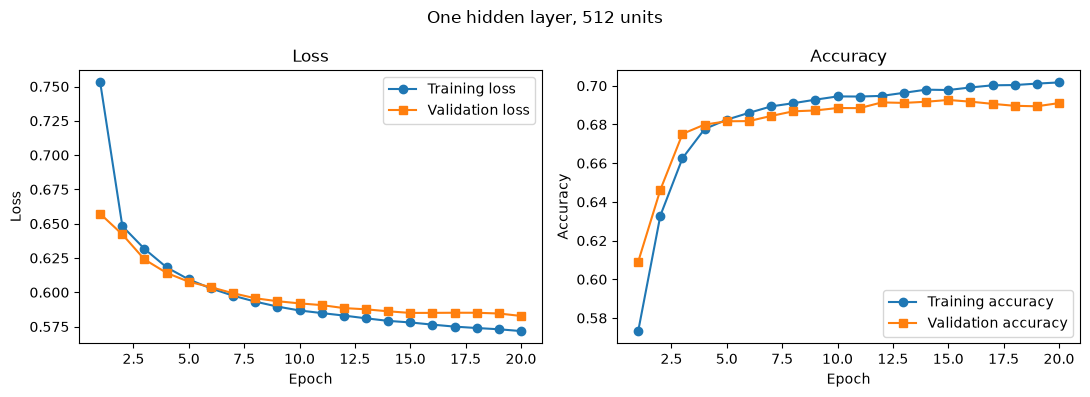

Validation loss is still falling at the last epoch (20).
The model has not overfit yet - train for longer or make it bigger (Step 6).


In [15]:
# Training curves. Plotting pattern adapted from Chollet and Watson (2026), §4.1.4 "Validating your approach", p.111.

def plot_history(history, title=""):
    # A dictionary with four keys: loss, val_loss, accuracy, val_accuracy
    # Each holds a list of 20 numbers, which is one per epoch
    h = history.history 
    # The x-axis for the graph (+1, so it doesn't start from 0)
    epochs = range(1, len(h["loss"]) + 1)

    # Two plots - one for loss and one for accuracy
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

    # Plot 1 - Training Loss and Validation Loss 
    ax1.plot(epochs, h["loss"], "o-", label="Training loss")
    ax1.plot(epochs, h["val_loss"], "s-", label="Validation loss")
    ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss"); ax1.legend(); ax1.set_title("Loss")

    # Plot 2 - Training Accuracy and Validation Accuracy
    ax2.plot(epochs, h["accuracy"], "o-", label="Training accuracy")
    ax2.plot(epochs, h["val_accuracy"], "s-", label="Validation accuracy")
    ax2.set_xlabel("Epoch"); ax2.set_ylabel("Accuracy"); ax2.legend(); ax2.set_title("Accuracy")

    # Specify titles and show plots
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

    # Gives the position of the smallest validation loss
    best = int(np.argmin(h["val_loss"])) + 1
    if best < len(epochs):
        print(f"Validation loss is lowest at epoch {best}, then rises.")
        print("That turning point is where the model stops generalising and starts memorising.")
    else:
        print(f"Validation loss is still falling at the last epoch ({best}).")
        print("The model has not overfit yet - train for longer or make it bigger (Step 6).")

plot_history(history, "One hidden layer, 512 units")


| Model | Accuracy | AUC |
|---|---|---|
| Coin flip | 0.5000 | - |
| Logistic regression | 0.6567 | 0.7298 |
| Dense 512 | 0.6911 | 0.7723 |


## What the Model's Results are saying?

### Beating Both Baselines...Just (What this means for Hypothesis 1)

* The good thing with the result was that the baseline was cleared. Chance was beaten by 19 points. Logistic regression is beaten by 3.4 points with an Area-Under-Curve gain of 0.043. This suggests there's a signal in the pixels and some is genuinely non-linear.

* To diagnose the issues with the intial training of the model, Chollet and Watson prescribe the idea that "to achieve the perfect fit, you must first overfit" - and this makes sense as they mention in order to see where the boundary lies, the model must cross it first. The goal of the research experiment initially should be to achieve a model that can overfit and generalise. In subsequent sections, I'll have the task of combatting overfitting (Chollet and Watson, 2026, §5.3, p.153).


### A matter of underfitting...

* Looking at the results, my model avoids 2 of the 3 common problems that Chollet and Watson say could be encountered. Number one is that training doesn't get started and training loss doesn't go down over time - in my model's case we don't encounter this, the training loss and validation loss both decrease very early on and continue to albeit at a more gradual rate as epochs progress. The second common problem is that training starts, but doesn't beat a common baseline. Objectively, my model does beat both of the baselines here - the coin-flip baseline and the logistic regression (not by a wide margin though). My model falls victim to the last problem that Chollet and Watson mention: training and validation loss both go down over time, beat the baseline, but don't seem able to overfit, which indicates underfitting.

* The answer to the first hypothesis is partially answered here. The results support it in direction, but are weaker than what I thought. I hypothesised that the Dense network would beat logistic regression by a wide margin and in the case here this is 3.4 points, which is larger than seed noise, but not a wide margin. I think this is honestly down to undertraining of the model and therefore the gap between logistic regression accuracy and the Dense network is "thin" to say the least. I will revisit hypothesis 1 in section 6.

* One of the headline figures here:

> Training accuracy peaks at 0.702 and Validation accuracy 0.691

* This is a gap of barely one point, with both the loss curves still falling at epoch 20 - which indicates that the model hasn't fit the training data well yet. To improve it, subsequent sections will require getting the model to overfit first (Section 6), and then improve the generalisation (Section 7).

### The model's error breakdown explained

* The error breakdown also paints an interesting picture about how the model classifies its images.

> False Positive Rate of 45.1% -> Nearly half of all genuine photographs are wrongly flagged as AI-generated.

> False Negative Rate at 16.7% -> Around one in six AI images slip through.

* The model is heavily biased towards shouting "fake" and this is a problem. Recall in Section 2, that I raised issue with the model flagging a real photograph of being fake, as this could mean accusing a real person of faking something - scaled up this means my model wrongly accuses around 4514 out of 10000 genuine photographs. I guess you could say it's quite 'paranoid' about the presence of fake images.

* Furthermore, I've used the results from the ROC-AUC function, which demonstrates something quite telling. The AUC result is 0.772, which is above accuracy at 0.691. The gap implies that the default 0.5 threshold could be holding the model back - the model's ranking is better than the thresholded decisions suggest and maybe a different cutoff would decrease the false-positive rate. The gap between high AUC and lower accuracy indicates that the model's ranking capability is strong, but operates at a suboptimal probability threshold (Fawcett, 2006).

---

## Improving the model in later sections

* From observing the graph of training and validation loss over time, it would seem that the model capacity isn't big enough. In a similar way to Chollet and Watson's MNIST example, the validation loss curve doesn't appear to peak and reverse course - my model is fitting, but not overfitting. This can be remedied by:

> Training for longer - instead of 20 epochs, just increasing the number of epochs

> Using a bigger model with more capacity. More layers, bigger layers.

> Different layers (out of scope for the project here, since the improvement would be convolutional layers, which I can't use).

<b>In the next sections I will:</b>

> Train for more epochs - there was no clear validation turn at 20 epochs.

> Test nine architectures with 1, 2 or 3 hidden layers, crossed with 64, 256 or 512 units.

> Run each one three times with different random seeds.

> Record the best validation accuracy and the epoch where validation loss turns upward.

---

# Section 6 — Scaling up: developing a model that overfits

The findings of section 5 have therefore changed the way I proceed with the experiment.

Running the full experiment on 20 epochs would not be a good idea. The accuracy and loss curves show that the 512-unit model had not finished learning after 20 epochs - both loss curves were still falling. If I was to run 9 network architectures at 20 epochs each, I would be comparing nine undertrained models, and the result wouldn't correctly tell which one is best.

There are two phases to how I will run my Section 6.

### Phase A - Find the optimal number of epochs

20 epochs was not enough. I'll take the same one-hidden layer 512-unit model and train it for longer - 100 epochs this time. The goal is to find where the validation loss stops falling and turns upward. The epoch count becomes the budget every configuration in the grid gets going forward.

Section 5 raised a key question: can the model architecture even overfit at all? If after 100 epochs, it still hasn't this could be an indication that the capacity of the model and not training time is a binding constraint.

512 units, 100 epochs:  accuracy 0.6935   AUC 0.7787
Error breakdown: {'false_positive_rate': 0.4453, 'false_negative_rate': 0.1678, 'false_positives': 4453, 'false_negatives': 1678}


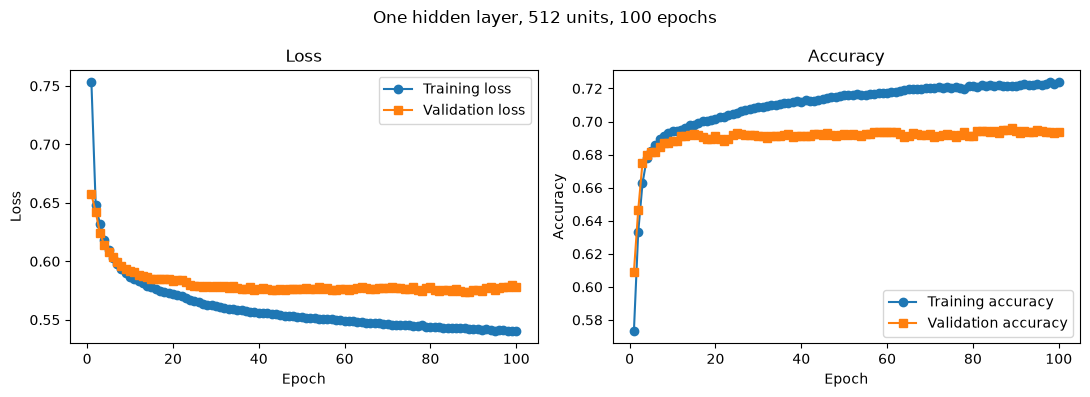

Validation loss is lowest at epoch 89, then rises.
That turning point is where the model stops generalising and starts memorising.
CPU times: user 11min 2s, sys: 2min 52s, total: 13min 54s
Wall time: 1min 50s


In [16]:
%%time
# PHASE A - how long does this architecture need and can it overfit at all?
# Same model as my Section 5, trained far longer. Nothing else changes.

keras.utils.set_random_seed(0) # Setting the seed - reproducible results.

model_long = build_model(hidden_layers=(512,)) # builds the model - one dense 512-unit layer

# Key difference here is my section 5.
history_long = model_long.fit(x_train, y_train, epochs=100, batch_size=512,
                              validation_data=(x_val, y_val), verbose=0)

scores_long = model_long.predict(x_val, verbose=0) # Uses validation set
print(f"512 units, 100 epochs:  accuracy {accuracy(y_val, scores_long):.4f}"
      f"   AUC {roc_auc(y_val, scores_long):.4f}")
print("Error breakdown:", error_breakdown(y_val, scores_long))

# Plots training curves
plot_history(history_long, "One hidden layer, 512 units, 100 epochs")

# NOTE the wall time this cell reports. Multiply it by 27 before committing to the grid.

### Interpretation of 100 epoch run

Optimising the number of epochs didn't move the needle in regards to accuracy and validation loss.

| Metric | 20 epochs | 100 epochs | Change |
|---|---|---|---|
| **Accuracy** | 0.6911 | 0.6935 | +0.24 pts |
| **AUC** | 0.7723 | 0.7787 | +0.64 pts |
| **FPR** | 45.14% | 44.53% | -0.6 pts |

The model plateaus at around 69%. The results also state that validation loss is lowest at epoch 89, which is deceptive because this is technically correct but if one is to observe the graph, the validation loss is already at a plateau and this could be easily misinterpreted. Going forward, I'll run the models for 50 epochs, which gives headroom for different model configurations.

The model appears to be overfitting after seeing this result. Training accuracy only mildly improves from 0.702 to 0.723 and validation accuracy improves marginally to 0.694. In addition, the training loss keeps dropping while the validation loss sits flat  - this is a true sign of overfitting.

### <b>What does this mean for the model though?</b>

The 512-unit dense layer model can memorise slightly, but validation performance stopped improving even with 80 epochs to go. Crucially, this suggests that epochs and training length were not optimisation - it could be the capacity.

Another question to still retain is: can a dense network actually extract from the flattened pixels at all?

In section 4, I stated how flattening destroys adjacency and is this showing the early signs that this is correct? I can't conclude yet, but the following will expand the model by testing a variety of architectures - if accuracy continues to plateau to 69% then this could suggest a limit to what is detectable. Climbing higher than this would suggest that capacity was a constraint. 


This is key because the CIFAKE paper by Bird and Lotfi utilises a convolutional layer model, which we are not using.

In [17]:
# Original code - IC
# Runs one configuration several times and reports the mean and the spread.
# This is what makes the error bars promised in Section 3 real rather than claimed.

def run_experiment(hidden_layers, epochs, seeds=(0, 1, 2),
                   dropout=0.0, l2=0.0, optimizer="adam", label=""):
    """Train one configuration once per seed and summarise the results.

    Returns a dict containing at least:
        label, hidden_layers, epochs,
        acc_mean, acc_std, auc_mean, auc_std,
        turn_epochs,  (the epoch with the lowest validation loss, one per seed),
        params
    """

    # Create empty lists to collect the per-seed results: accuracy, AUC, and the turn epoch.
    accuracies, auc, turn_epochs = [], [], []
    
    for seed in seeds:
        # Set the random seed so each run is reproducible
        keras.utils.set_random_seed(seed)

        # For the optimizer experiment later
        # optimizer may be a string ("adam) or a callable returning a fresh optimizer object
        opt = optimizer() if callable(optimizer) else optimizer
        
        # Build the model, passing through hidden_layers, dropout, l2, optimizer
        model = build_model(hidden_layers=hidden_layers, dropout=dropout, l2=l2, optimizer=opt)
        params = model.count_params()
        
        # Fit the model. Keep the returned history - you need it for the turn epoch.
        # history_.history holds four keys: loss, val_loss, accuracy, val_accuracy 
        # -> each holds a list of 50 numbers (epochs), one per epoch
        history_ = model.fit(x_train, y_train, epochs=epochs, batch_size=512,
                              validation_data=(x_val, y_val), verbose=0)

        # Predict on x_val
        scores_ = model.predict(x_val, verbose=0) # Uses validation set
        
        # Find the epoch with the lowest val_loss (np.argmin, then +1)
        min_val_loss_epoch = int(np.argmin(history_.history["val_loss"])) + 1

        # Append all three results to the lists
        # Compute accuracy and roc_auc using my functions from earlier
        accuracies.append(accuracy(y_val, scores_))
        auc.append(roc_auc(y_val, scores_))
        turn_epochs.append(min_val_loss_epoch)
        

    # Compute mean and standard deviation for accuracy and AUC (np.mean, np.std)
    acc_mean = float(np.mean(accuracies))
    acc_std = float(np.std(accuracies, ddof=1))
    auc_mean = float(np.mean(auc))
    auc_std = float(np.std(auc, ddof=1))
    
    # Return a dict
    return {
        "label": label,
        "hidden_layers": hidden_layers,
        "epochs": epochs,
        "acc_mean": acc_mean,
        "acc_std": acc_std,
        "auc_mean": auc_mean,
        "auc_std": auc_std,
        "turn_epochs": turn_epochs,
        "params": params
    }

### Phase B - The Capacity Grid

Overall there will be nine architectures: testing depths of 1, 2, or 3 hidden layers, crossed with widths of 64, 256, or 512 units. On top of this, three seeds for testing would equal a total of 27 training runs. For each, I'll record the best validation accuracy and the epoch at which validation loss turns. 

The rule for evaluating these results:

> ### A model configuration counts as better only if it beats another by more than one standard deviation across seeds.

In addition, the experiment borrows from Chollet and Watson's own remedy for underfitting, which was to go from one hidden layer (my current model configuration) to two hidden layers (Chollet and Watson, 2026, §5.3.3, pp.155–157)and in the IMDB film-review model two layers was utilised (Chollet and Watson, 2026, §4.1.3, p.108).



In [18]:
# PHASE B - the capacity grid.
# Nine architectures, three seeds each, at the epoch budget Phase A identified.
# there will be nine architectures: testing depths of 1, 2, or 3 hidden layers, crossed with widths of 64, 256, or 512 units.

# Set from the Phase A result, not from a guess
GRID_EPOCHS = 50

# Define the depths and widths to test
depths = [1, 2, 3]
widths = [64, 256, 512]

grid_results = [] # Will store all 

for depth in depths:
    for width in widths:
        # Turn (depth, width) into the tuple build_model expects.
        # depth 2, width 256  ->  (256, 256)
        hidden_layers = (width,) * depth
        
        # Building a repeatable label to tell which model this is
        run_label = f"{depth} x {width}"
        
        # Print the label BEFORE the run starts
        print(run_label)

        # Start the clock and print the label BEFORE the run starts
        t0 = time.time()
        print(run_label, end=" ... ", flush=True)
        
        # Call run_experiment and append the returned dict to grid_results
        grid_results.append(run_experiment(hidden_layers=hidden_layers, epochs=GRID_EPOCHS, seeds=[0, 1, 2], 
                                           dropout=0.0, l2=0.0, optimizer="adam", label=run_label))

        # How long that configuration took
        print(f"{time.time() - t0:.0f}s")
        
        # Saves grid_results to disk (e.g. json.dump or np.save) so a crash or an
        # accidental kernel restart does not cost you the entire sweep
        with open("grid_results.json", "w") as f:
            json.dump(grid_results, f, indent=2)

print(f"Saved {len(grid_results)} configurations to grid_results.json")

1 x 64
1 x 64 ... 63s
1 x 256
1 x 256 ... 110s
1 x 512
1 x 512 ... 169s
2 x 64
2 x 64 ... 65s
2 x 256
2 x 256 ... 125s
2 x 512
2 x 512 ... 195s
3 x 64
3 x 64 ... 67s
3 x 256
3 x 256 ... 138s
3 x 512
3 x 512 ... 223s
Saved 9 configurations to grid_results.json


In [19]:
# Reports the best configurations (acc and auc) 
def report_best(results, mean_key, std_key, metric_name):
    """Report the best configuration and anything indistinguishable from it."""
    ranked = sorted(results, key=lambda r: r[mean_key], reverse=True)
    best = ranked[0]
    best_mean, best_std = best[mean_key], best[std_key]

    # Prints the best by metric name (will be acc or auc)
    print(f"\nBest by {metric_name}: {best['label']} "
          f"({best_mean:.4f} ± {best_std:.4f})")

    # everything whose gap to the best is smaller than the best's own spread
    within = [r for r in ranked[1:] if best_mean - r[mean_key] <= best_std]

    if within:
        names = ", ".join(r['label'] for r in within)
        print(f"Within one standard deviation: {names}")
        print(f"These cannot be separated from {best['label']} by this measure.")
    else:
        print(f"{best['label']} is a clear winner — no other configuration "
              f"falls within {best_std:.4f} of it.")

In [20]:
# Results table for the grid.
from IPython.display import Markdown, display
import numpy as np

# Function that will be used here, Section 7, and Section 8
def print_results_table(results):
    lines = [
        "| Config | Params | Val accuracy | AUC | Turn epoch |",
        "|---|---|---|---|---|"
    ]

    # 1. Format and add a row for each configuration
    for r in results:
        # Take the mean of turn_epochs since this is a list of three numbers
        turn_epoch_mean = np.mean(r['turn_epochs'])

        # Format parameters as a number with commas (e.g. 196,737)
        param_str = f"{r['params']:,}"

        row = (
            f"| {r['label']} "
            f"| {param_str} "
            f"| {r['acc_mean']:.4f} ± {r['acc_std']:.4f} "
            f"| {r['auc_mean']:.4f} ± {r['auc_std']:.4f} "
            f"| {turn_epoch_mean:.1f} |"
        )
        lines.append(row)

    # Display Markdown table
    display(Markdown("\n".join(lines)))

    # Report the best configurations using report_best()
    report_best(results, 'acc_mean', 'acc_std', 'validation accuracy')
    report_best(results, 'auc_mean', 'auc_std', 'AUC')
    

In [21]:
# Load the saved results (or skip this if grid_results is still in memory)
with open("grid_results.json") as f:
    grid_results = json.load(f)

print(f"Loaded {len(grid_results)} configurations\n")

print_results_table(grid_results)

Loaded 9 configurations



| Config | Params | Val accuracy | AUC | Turn epoch |
|---|---|---|---|---|
| 1 x 64 | 196,737 | 0.6603 ± 0.1394 | 0.7200 ± 0.1913 | 23.0 |
| 1 x 256 | 786,945 | 0.7182 ± 0.0607 | 0.7948 ± 0.0698 | 46.0 |
| 1 x 512 | 1,573,889 | 0.7262 ± 0.0314 | 0.8127 ± 0.0312 | 46.7 |
| 2 x 64 | 200,897 | 0.7816 ± 0.0159 | 0.8744 ± 0.0070 | 36.7 |
| 2 x 256 | 852,737 | 0.7959 ± 0.0075 | 0.8876 ± 0.0067 | 31.3 |
| 2 x 512 | 1,836,545 | 0.8032 ± 0.0085 | 0.8889 ± 0.0039 | 20.3 |
| 3 x 64 | 205,057 | 0.7937 ± 0.0070 | 0.8843 ± 0.0043 | 45.3 |
| 3 x 256 | 918,529 | 0.7952 ± 0.0083 | 0.8843 ± 0.0042 | 22.0 |
| 3 x 512 | 2,099,201 | 0.7984 ± 0.0124 | 0.8788 ± 0.0099 | 21.0 |


Best by validation accuracy: 2 x 512 (0.8032 ± 0.0085)
Within one standard deviation: 3 x 512, 2 x 256, 3 x 256
These cannot be separated from 2 x 512 by this measure.

Best by AUC: 2 x 512 (0.8889 ± 0.0039)
Within one standard deviation: 2 x 256
These cannot be separated from 2 x 512 by this measure.


<b>Figure 1 - Grid Results configuration Table</b>

In [22]:
# The grid figure.
from collections import defaultdict

def plot_grid_results(results):
    """Plots mean validation accuracy for all nine configurations.
       Shows the standard deviation across seeds as error bars.
    """
    # 1. Group data by depth (number of layers)
    # Maps depth -> {widths: [], means: [], stds: []}
    grouped = defaultdict(lambda: {'widths': [], 'means':[], 'stds': []})

    for r in results:
        # Extract depth and width from hidden_layers (e.g. [64, 64] -> depth=2, width=64)
        depth = len(r['hidden_layers'])
        width = r['hidden_layers'][0]

        # Set the width, acc_mean and acc_std for each depth
        grouped[depth]['widths'].append(width)
        grouped[depth]['means'].append(r['acc_mean'])
        grouped[depth]['stds'].append(r['acc_std'])

    # Create a new figure
    plt.figure(figsize=(8, 5))

    # Different markers per depth
    markers = {1: '-o', 2: '-s', 3: '-^'}

    # The different widths sorted 
    width_order = sorted({r['hidden_layers'][0] for r in results})   # [64, 256, 512]

    # 2. Plot a line for each depth group
    for depth in sorted(grouped.keys()):
        data = grouped[depth] # Gets that depth from the grouped dict
        
        # Sort by width so points line up correctly along the x-axis
        sort_idx = np.argsort(data['widths'])
        widths = np.array(data['widths'])[sort_idx]
        means = np.array(data['means'])[sort_idx]
        stds = np.array(data['stds'])[sort_idx]

        xs = [width_order.index(w) for w in widths] # 0, 1, 2

        # Error bar shows the visible spread amongst each seed
        plt.errorbar(
            xs, 
            means, 
            yerr=stds, 
            fmt=markers[depth], 
            capsize=5, 
            capthick=1.5,
            label=f'{depth} hidden layer' + ('' if depth == 1 else 's')
        )

    # 3. Formatting
    plt.xticks(range(len(width_order)), [str(w) for w in width_order])
    plt.xlabel('Layer Width')
    plt.ylabel('Validation Accuracy (Mean ± Std)')
    plt.title('Validation Accuracy Across Grid Configurations')
    plt.grid(True, linestyle='--', alpha=0.6)

    # This shows the logistic regression baseline - for visual comparison
    plt.axhline(0.6567, linestyle=':', color='grey',
            label='Logistic regression baseline')
    plt.legend()
    plt.tight_layout()
    plt.show()

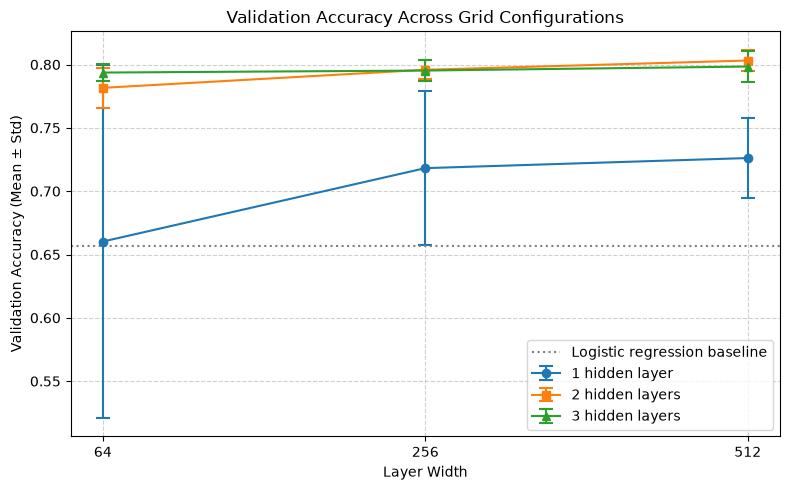

In [23]:
plot_grid_results(grid_results)

<b>Figure 2 - Validation Accuracy Across Grid Configurations</b>

## Evaluation of Results from Section 6 (Phase B)

Section 6 concludes with some extremely interesting key findings that validate previous arguments made in Sections 3 and 4 and also an early hypothesis.

After running Phase B here are the key findings:

<br>

> ## The Depth of the model dominates over the width.

I find this particularly interesting. Phase B tests 3 different widths: 64, 256 and 512-unit Dense layers. It also tests 3 different depths: 1, 2 and 3 stacks of these Dense layers.

Figure 1 details the 2x64-unit Dense Layer architecture totalled 200,897 parameters and over three runs scored an average accuracy of 0.7816. Contrast this with the 1x512-unit Dense Layer architecture that has 1,573,889 total parameters - it scored an average accuracy of 0.7262. Here, nearly eight times fewer parameters scored 5.5 points better. 

What does this mean? Capacity and depth are not the same thing for this experiment. In section 4, I specified Chollet and Watson's remarks about how there were two levers for greater representational power (technically three, but I'm not using conv layers). One interpretation is that of the two levers identified in Section 4 that were available for my experiment, adding a second layer allowed the network to build features from features and a wider single layer only gives more ways to perform one transformation. (Chollet and Watson, 2026, p.155).


<br>


> ## What AUC Says about the model architecture?

The AUC metric I've calculated for each network has gone rather unnoticed until this point. 

For a recap, AUC measures how well the model distinguishes between two classes with a score ranging between 0 and 1. A score closer to 1 indicates a better prediction and accuracy at separating classes, whereas a score of 0.5 would be no better than a random coin toss.

On all nine models, figure 1 shows AUC is consistently 8-9 points above accuracy. In section 5, the result showed this once. Now the models rank well but the 0.5 cutoff converts that ranking into decisions quite poorly. This indicates there is accuracy unclaimed (Fawcett, 2006).

However, it should be noted that on both accuracy and AUC, depths of 2-3 hidden layers beat depth 1 and this means the threshold shouldn't be the headline conclusion from Section 6.  At 3 layers, the accuracy and AUC metrics diverge. 3x512 is the second-highest scoring accuracy model at 0.7984, but it is actually the weakest deep model by AUC sitting at 0.8788 and going off accuracy alone would not have told the complete story.

For the result, AUC helps to narrow down which models should 'survive' into Section 7. The accuracy results had four configurations within one standard deviation of the best and with AUC, only the 2x256 network does. Interestingly, both of the surviving network architectures have two hidden layers, whilst the three-layer models offered no major benefit for the extra hidden layer and more compute.

<br>


> ## Gains stagnated after two layers.

Accuracy results on the two and three-layer network architectures were the highest, but the gains between two to three layers was minimal. From one to two layers a gain of 9 points in accuracy can be seen, but from two to three, a gain of 0.3. 

In addition four of the configurations sit within one standard deviation of the best. The 2x256-unit model reaches the same accuracy within the spread as the 2x512-unit model, but with less than half the paramters - this favours the smaller model as trying to add complexity for minimal gain is not better.


<br>


> ## Variance collapsed as depth increased.

The results from the table above show how variance collapses as the number of layers increased. On the 1x64-unit model, the standard deviation of ±0.139 is the highest seen. By contrast increasing to two layers of 512 units drops all the way to ±0.0085. 

In the figure 2 above, the logistic regression baseline is drawn as a way to compare the different networks' validation accuracy and their error spread. From the 64-unit models to the 256-unit models the spread varies hugely. The 256-unit worst case touches the regression baseline.

An important thing to notice here is that the lower bound of the 1x64 model's accuracy falls below the logistic regression baseline, indicating that at least one seed performed worse than the linear model. This is visible from the error bar crossing the dotted line in figure 2. We can conclude that for this research question that a single layer network is unreliable - performing three seeds here was a good idea since one reading may have given a false sense of achievement for the single layer model.


Alongside accuracy, AUC paints a similar picture. AUC is about half as variable across seeds for every depth-2 and depth-3 model ( 2x512 has ±0.0039 for AUC, whilst accuracy is 0.0085. It doesn't depend on the cutoff so is not sensitive to small shifts in the score distribution. There is an exception to this and that is for depth-1 models where AUC is more variable than the accuracy (±0.1913 and ±0.0698 at 64 and 256 unit layers).

<br>



> ## H1 Revisited - Higher Accuracy

After the model's run in Section 5, I stated how H1 was only partially answered. The results supported the direction, but were much weaker than anticipated, since I hypothesised that the Dense network would beat logistic regression by a wide margin. At that point, I put it down to undertraining of the model and stated I would revisit this in Section 6.

Here's the results after Section 6:

> ### Section 5 accuracy gap over logistic regression: 3.4 points
> ### Section 6 accuracy gap over logistic regression: 14.7 points

The 2x512 model architecture came in at a mean accuracy of 0.8032 ± 0.0085. H1 is now strongly supported with this latest set of training runs. The weak reading from Section 5 was evidence that the overall architecture was inadequate and required a higher capacity instead of my original thinking that the model wasn't overfitting due to a low epoch run.

* At the end of Section 5, the 1.5 million parameter model lagged 24 points behind the 92.98% convolutional benchmark set by Bird and Lotfi.
* By the end of Section 6, this gap has close to halved and the model sits at 12.7 points behind the benchmark.

> 2 x 512 Unit Layer | 1,836,545 Parameters | 0.8032 ± 0.0085 accuracy | 0.8889 ± 0.0039 AUC | 20.3 epoch achieved


<br>


Going forward and after running all nine architectures, the 2x512 Dense layer model will be what I continue with. It actually achieved its overfitting earliest at 20.3 epochs. Compare this with the 2x256 network, which turned at 31.3 epochs. Chollet and Watson suggest finding the model that overfits before then regularising and from this section I'm moving forward with the 2x512 network - the 2x256 network is the parsimonious alternative.


---

# Section 7 — Regularising and tuning

After Section 6's results, the 2x512 Dense layer model is what I will be continuing with. The model began overfitting at epoch 20 on average and this section concerns itself with fighting the overfitting. 

This will be done in 3 ways:

- **Dropout** at 0.0, 0.2 and 0.5
- **L2 weight decay** at 0, 0.0001 and 0.001
- **Reducing capacity** — a smaller network, which is the book's first recommended remedy (Chollet and Watson, 2026, p.161).

Comparing three remedies is more systematic than applying one and declaring success.

### Understanding Dropout

The Dropout paper by Srivastava, Hinton, Krizhevsky, Sutskever and Salakhutdinov, was published in the Journal of Machine Learning Research, Volume 15 in 2014. It proposes some key ideas that are useful in my research experiment.

The paper's central claim is this:

> <h3>The key idea is to randomly drop units (along with their connections) from the neural network during training. This prevents units from co-adapting too much.</h3>(Srivastava et al., 2014)

Dropout as a regularisation technique makes the neural network good at learning patterns that generalise beyond training data. It's more than just randomly switching off units and the paper offers two fundamental ideas about dropout:

* <b>Preventing co-adaption</b> - Units can't rely on specific other units being present, so they can't form these chains where one neuron depends on another. Each has to be useful more independently.
* <b>An implicit ensemble</b> - Every training pass uses a different thinned network so training becomes an enormous collection of networks that share weights. At test time, using the full network (with scaled-down weights) is an approximation of the average over all the thinned networks.

In [24]:
# 7.1 - REGULARISATION. Three remedies compared on the same base architecture.
# Base is 2 x 512, carried forward from Section 6 because it overfits earliest.
# In experiment, I'll never run dropout and l2 at the same time. Each sweep only varies one thing.
# The only exception is at the end, where I take the best dropout and l2 and run a single configuration with both.
BASE_LAYERS = (512, 512) # Same base model layers throughout so define here

REG_EPOCHS  = 50 # Same budget as the grid, so results stay comparable 

reg_results = [] # This is where I will store the results

# Define lists for dropouts and weights to be tested.
dropouts = [0.0, 0.2, 0.5]
l2_weights = [0.0, 0.0001, 0.001]


def run_reg_experiment(dropout=0.0, l2_weight=0.0, run_label=None):
    """ Run regularisation experiment on dropouts and l2_weights
        Default values for dropout and l2_weights
    """
    # Create the run_label
    if run_label is None:
        run_label = f"dropout {dropout}" if dropout > 0 or l2_weight == 0 else f"L2 {l2_weight}"
        
    # Will measure the time again, as in Section 6
    t0 = time.time()
    print(run_label, end=" ... ", flush=True)

    # Call the run_experiment and append results to reg_results
    # Run three seeds again
    reg_results.append(run_experiment(hidden_layers=BASE_LAYERS, epochs=REG_EPOCHS, seeds=[0, 1, 2],
                                      dropout=dropout, l2=l2_weight, optimizer="adam", label=run_label))

    # How long the configuration took
    print(f"{time.time() - t0:.0f}s")

    # Save to reg_results after every experiment in case of crash or kernel restart
    # Save to reg_results.json - not overwriting grid_results.json
    with open("reg_results.json", "w") as f:
        json.dump(reg_results, f, indent=2)
    

# The goal with testing dropout and L2 is to see which regularisation remedy helps and by how much.
# 0.0 for both dropout and l2 will be reference points (unregularised)
for d in dropouts:
    run_reg_experiment(dropout=d, l2_weight=0.0)

# Skip the first - already been run
for l in l2_weights[1:]:
    run_reg_experiment(dropout=0.0, l2_weight=l)

print(f"Saved {len(reg_results)} configurations to reg_results.json")

dropout 0.0 ... 188s
dropout 0.2 ... 210s
dropout 0.5 ... 256s
L2 0.0001 ... 203s
L2 0.001 ... 215s
Saved 5 configurations to reg_results.json


In [25]:
# Capacity comparison with original results but only at 2 Dense Layers
# Reducing the capacity (Still 50 epochs, seeds [0,1,2], no dropout and no l2).
capacity_labels = ["2 x 512", "2 x 256", "2 x 64"]
capacity_results = [r for r in grid_results if r["label"] in capacity_labels]

print("Capacity reduction as a regularisation remedy:")
print_results_table(capacity_results)

print("Dropout and L2 sweeps:")
print_results_table(reg_results)

Capacity reduction as a regularisation remedy:


| Config | Params | Val accuracy | AUC | Turn epoch |
|---|---|---|---|---|
| 2 x 64 | 200,897 | 0.7816 ± 0.0159 | 0.8744 ± 0.0070 | 36.7 |
| 2 x 256 | 852,737 | 0.7959 ± 0.0075 | 0.8876 ± 0.0067 | 31.3 |
| 2 x 512 | 1,836,545 | 0.8032 ± 0.0085 | 0.8889 ± 0.0039 | 20.3 |


Best by validation accuracy: 2 x 512 (0.8032 ± 0.0085)
Within one standard deviation: 2 x 256
These cannot be separated from 2 x 512 by this measure.

Best by AUC: 2 x 512 (0.8889 ± 0.0039)
Within one standard deviation: 2 x 256
These cannot be separated from 2 x 512 by this measure.
Dropout and L2 sweeps:


| Config | Params | Val accuracy | AUC | Turn epoch |
|---|---|---|---|---|
| dropout 0.0 | 1,836,545 | 0.8032 ± 0.0085 | 0.8889 ± 0.0039 | 20.3 |
| dropout 0.2 | 1,836,545 | 0.7871 ± 0.0096 | 0.8783 ± 0.0038 | 48.3 |
| dropout 0.5 | 1,836,545 | 0.6793 ± 0.0737 | 0.8211 ± 0.0076 | 34.7 |
| L2 0.0001 | 1,836,545 | 0.8030 ± 0.0101 | 0.8967 ± 0.0014 | 34.7 |
| L2 0.001 | 1,836,545 | 0.7926 ± 0.0072 | 0.8856 ± 0.0070 | 38.7 |


Best by validation accuracy: dropout 0.0 (0.8032 ± 0.0085)
Within one standard deviation: L2 0.0001
These cannot be separated from dropout 0.0 by this measure.

Best by AUC: L2 0.0001 (0.8967 ± 0.0014)
L2 0.0001 is a clear winner — no other configuration falls within 0.0014 of it.


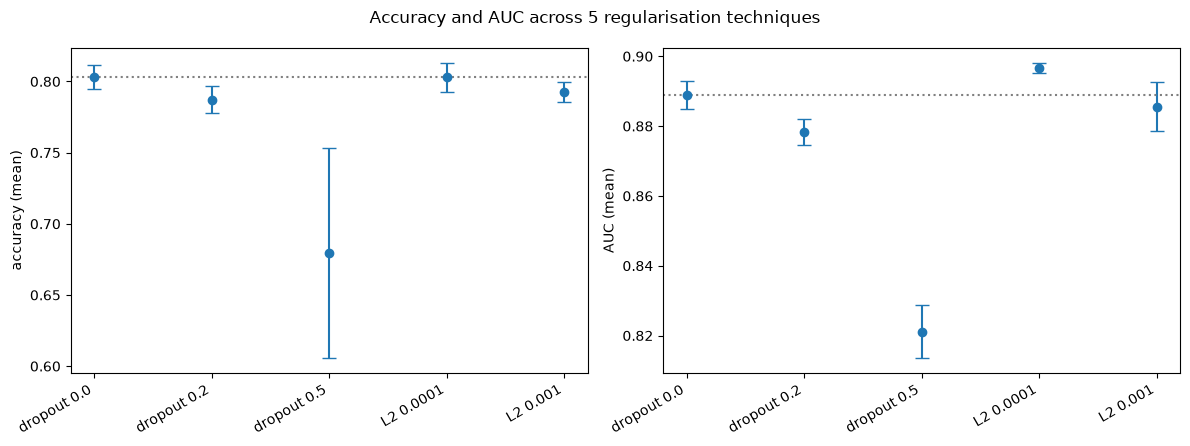

In [26]:
# A plot to show the accuracy and AUC across the five regularisation configurations.

def plot_reg_results(results, title=""):
    """Two panels: accuracy on the left, AUC on the right, both with error here"""

    # Pulls 5 lists for the plot out of the results
    labels = [r['label'] for r in results]
    acc_means = [r['acc_mean'] for r in results]
    acc_stds = [r['acc_std'] for r in results]
    auc_means = [r['auc_mean'] for r in results]
    auc_stds = [r['auc_std'] for r in results]

    # X-axis for both plots
    xs = range(len(results))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

    # Plot 1 - Accuracy
    ax1.errorbar(xs, acc_means, yerr=acc_stds, fmt='o', capsize=5)
    ax1.set_ylabel("accuracy (mean)"); 

    # Plot 2 - AUC 
    ax2.errorbar(xs, auc_means, yerr=auc_stds, fmt='o', capsize=5)
    ax2.set_ylabel("AUC (mean)"); 

    # Configuration names on the x-axis of both panels
    ax1.set_xticks(xs)
    ax1.set_xticklabels(labels, rotation=30, ha='right')
    ax2.set_xticks(xs)
    ax2.set_xticklabels(labels, rotation=30, ha='right')

    # A horizontal line to show baseline dropout 0.0 
    ax1.axhline(acc_means[0], linestyle=':', color='grey')
    ax2.axhline(auc_means[0], linestyle=':', color='grey')  

    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

plot_reg_results(reg_results, "Accuracy and AUC across 5 regularisation techniques")

<b>Figure 3 - Validation accuracy (left) and AUC (right) for five regularisation configurations on the 2 × 512 base architecture, with error bars showing the standard deviation across three seeds. The dotted line marks the unregularised baseline (dropout 0.0). L2 0.0001 is the only configuration to exceed the baseline on AUC and does so with the smallest spread of any run.</b>

---

## Evaluating Dropout and L2 Regularisation on the model

Overall the results aren't great for what dropout and L2 were able to achieve for the model (in terms of accuracy).

#### None of the three remedies improved accuracy

| Remedy | Best result | vs baseline (0.8032) |
| :--- | :--- | :--- |
| Reducing capacity | 2 × 512 wins outright | no gain |
| Dropout | 0.0 wins outright | no gain |
| L2 | 0.0001 ties on accuracy | no gain |

* <b>Regularisation didn't really help</b>. That's because regularisation is supposed to combat overfitting and my model was only barely overfitting. Section 6 of my results established that the ceiling wasn't a generalisation gap, but that there was a limit on what a network of Dense layers can extract from flattened pixels (something I was wary of in Section 4).

### Reducing Capacity...as expected

* Onto the 3 remedies, Chollet and Watson's easiest fix was reducing capacity(Chollet and Watson, 2026, p.161). This proved to be ineffective and 2x512 still had the best accuracy. This continues with what was established in Section 6 that shrinking the network trades away fitting ability without buying any generalisation.

### Dropout...the disappointment

* Dropout was actively harmful to the accuracy. Dropout(0.2) cost the accuracy 1.6 points and Dropout(0.5) was dreadful, costing it 12.4 points and increasing variance by nine times.

* The change in variance shows that reducing the effective capacity during each training pass makes the training unstable across seeds.

* The dropout did work when it came to turn_epoch and when overfitting set in. From dropout(0.0) to dropout(0.2) the turn_epoch went from 20.3 to 48.3. It did as Srivastava et al. suggested: it delayed overfitting clearly, but didn't improve generalisation.

### L2...a similar story with one silver lining

* L2 0.0001 was the only genuine positive to come from these runs.
  
* Accuracy was practically identical to the baseline at 0.8030.

* However, AUC was 0.8967 - This was the highest of any run in the research experiment so far in any section. With a turn_epoch of 34.7

* This is followed up with a variance of ± 0.0014, which is the most stable configuration for the entire project and less than half the baseline's spread.

* This makes L2 0.0001 the best configuration up to this point based on the AUC and reinforces the use of this metric alongside accuracy. Going on accuracy alone would have suggested that l2 didn't make a difference and it was better to remain with the baseline, but this result here suggests otherwise.


## How this changes the rest of the experiment?

I had planned to run a combined experiment at the end of section 7: the best dropout with the best L2 at the end. However, the best dropout was 0.0 and the best l2 was 0.0001 and I won't be running this experiment later.

In [27]:
# 7.2 - OPTIMISER AND LEARNING RATE.
# Define the configurations for optimizer and learning rate
# Passed in as lambda functions so each run is a new object 
opt_configs = [
    ("Adam 0.0001", lambda: keras.optimizers.Adam(learning_rate=0.0001)),
    ("Adam 0.01", lambda: keras.optimizers.Adam(learning_rate=0.01)),
    ("RMSprop 0.0001", lambda: keras.optimizers.RMSprop(learning_rate=0.0001)),
    ("RMSprop 0.001", lambda: keras.optimizers.RMSprop(learning_rate=0.001)),
    ("RMSprop 0.01", lambda: keras.optimizers.RMSprop(learning_rate=0.01)),
    ("SGD 0.01", lambda: keras.optimizers.SGD(learning_rate=0.01)),
    ("SGD 0.1", lambda: keras.optimizers.SGD(learning_rate=0.1)),
]

opt_results = []

# Loop over the configurations, call run_experiment, append, save
for opt in opt_configs:
    # Separate the label and factory
    label=opt[0]
    factory=opt[1]
    
    # Will measure the time again, as in Section 6
    t0 = time.time()
    print(label, end=" ... ", flush=True)

    # Run each experiment with the optimizer configuration
    opt_results.append(run_experiment(hidden_layers=BASE_LAYERS,
                       epochs=REG_EPOCHS,
                       seeds=[0, 1, 2],
                       dropout=0.0,
                       l2=0.0,
                       optimizer=factory,
                       label=label))

    print(f"{time.time() - t0:.0f}s")

    # Save to opt_results.json
    with open("opt_results.json", "w") as f:
        json.dump(opt_results, f, indent=2)

# Add the default adam configuration
adam_default = [r for r in reg_results if r["label"] == "dropout 0.0"]
# Display the results
print_results_table(adam_default + opt_results)

Adam 0.0001 ... 203s
Adam 0.01 ... 198s
RMSprop 0.0001 ... 198s
RMSprop 0.001 ... 197s
RMSprop 0.01 ... 198s
SGD 0.01 ... 166s
SGD 0.1 ... 163s


| Config | Params | Val accuracy | AUC | Turn epoch |
|---|---|---|---|---|
| dropout 0.0 | 1,836,545 | 0.8032 ± 0.0085 | 0.8889 ± 0.0039 | 20.3 |
| Adam 0.0001 | 1,836,545 | 0.8226 ± 0.0078 | 0.9109 ± 0.0018 | 22.7 |
| Adam 0.01 | 1,836,545 | 0.7547 ± 0.0207 | 0.8530 ± 0.0036 | 34.0 |
| RMSprop 0.0001 | 1,836,545 | 0.8162 ± 0.0237 | 0.9100 ± 0.0052 | 47.7 |
| RMSprop 0.001 | 1,836,545 | 0.7849 ± 0.0177 | 0.8729 ± 0.0086 | 34.7 |
| RMSprop 0.01 | 1,836,545 | 0.5323 ± 0.0559 | 0.5775 ± 0.1343 | 17.7 |
| SGD 0.01 | 1,836,545 | 0.7750 ± 0.0299 | 0.8855 ± 0.0016 | 48.7 |
| SGD 0.1 | 1,836,545 | 0.8018 ± 0.0054 | 0.8944 ± 0.0026 | 36.7 |


Best by validation accuracy: Adam 0.0001 (0.8226 ± 0.0078)
Within one standard deviation: RMSprop 0.0001
These cannot be separated from Adam 0.0001 by this measure.

Best by AUC: Adam 0.0001 (0.9109 ± 0.0018)
Within one standard deviation: RMSprop 0.0001
These cannot be separated from Adam 0.0001 by this measure.


<b>Figure 4 - Results from All Optimizer Runs</b>

---

## Evaluating the Optimizer Experiment

> <h3>Adam 0.0001 provided a genuine improvement in model performance.</h3>
>
> <h3>Accuracy: 0.8226 ± 0.0078 | AUC: 0.9109 ± 0.0018</h3>

<br>
The Adam 0.0001 optimiser configuration had an improved accuracy of 1.94 points over the baseline (using Adam 0.001). This is a real improvement and the first true one for this section.

The AUC of 0.9109 is the highest figure anywhere in the project, beating L2 0.0001's 0.8967, with a smaller error bar too.

<b>Choosing which optimizer seems to matter less overall than the actual learning rate.</b> This is the key finding.

| Rate | Adam | RMSprop |
| :--- | :--- | :--- |
| 0.0001 | 0.8226 | 0.8162 |
| 0.001 | 0.8032 | 0.7849 |
| 0.01 | 0.7547 | 0.5323 |

Adam and RMSprop aren't separated by much, but going down each column and the difference is significant. At RMSprop 0.01, the learning rate is too high and the accuracy crumbles to 0.5323 with an AUC of 0.5775 ± 0.1343. That's barely above chance and the spread is amongst some of the highest seen.

So the choice of algorithm barely matters, only the choice of rate dominates here.

Applying different learning rates depending on the optimizer was key. Applying the same used for ADAM to SGD would have lookedl like this:

* SGD 0.1 scoring 0.8018, which is similar to Adam 0.001
* However, going for a much smaller rate like what Adam uses would mean, I would have seen SGD as a poor optimizer, but this isn't the case. It just needs a higher learning rate.

## One Last Run.

I'll now do a training run that uses L2 0.0001, and Adam 0.0001, which are the regulariser and optimizer the results showed to be the most effective.

I'm now testing the one combination that matters. The training sweeps in this section assume the winners don't interact, but here's why that isn't the case: L2 0.0001, which won used Adam as the optimizer at 0.001, but is it still the best once the Adam optimizer's learning rate becomes 0.0001? This is what the following run tests.

The following run will also test what epoch count was optimal:

* L2 0.0001 (with Adam 0.001) turns at 34.7
* Adam 0.0001 (with no L2) turns at 22.7

In [28]:
# Neither iteration has tested L2 0.0001 and Adam 0.0001 together, so the epoch count for the final count is unknown still.
# This run should tell that and make it clear whether L2 still helps once the learning rate is right.

# Display time taken and label
t0 = time.time()
print("L2 0.0001 + Adam 0.0001", end=" ... ", flush=True)

# Run now with new l2 and optimizer together
combo = run_experiment(hidden_layers=BASE_LAYERS,
                       epochs=REG_EPOCHS,
                       seeds=[0, 1, 2],
                       dropout=0.0,
                       l2=0.0001,
                       optimizer=lambda: keras.optimizers.Adam(learning_rate=0.0001),
                       label="L2 0.0001 + Adam 0.0001")

print(f"{time.time() - t0:.0f}s")

# Save it.
with open("combo_result.json", "w") as f:
    json.dump([combo], f, indent=2)

L2 0.0001 + Adam 0.0001 ... 226s


In [29]:
# Compare the combination against each of its parts.
adam_only = [r for r in opt_results if r["label"] == "Adam 0.0001"]
l2_only   = [r for r in reg_results if r["label"] == "L2 0.0001"]

print("The combination against each of its parts:")
print_results_table(l2_only + adam_only + [combo])

print("\nTurn epochs per seed:", combo["turn_epochs"])
print(f"Mean turn epoch: {np.mean(combo['turn_epochs']):.1f}")

The combination against each of its parts:


| Config | Params | Val accuracy | AUC | Turn epoch |
|---|---|---|---|---|
| L2 0.0001 | 1,836,545 | 0.8030 ± 0.0101 | 0.8967 ± 0.0014 | 34.7 |
| Adam 0.0001 | 1,836,545 | 0.8226 ± 0.0078 | 0.9109 ± 0.0018 | 22.7 |
| L2 0.0001 + Adam 0.0001 | 1,836,545 | 0.8153 ± 0.0220 | 0.9123 ± 0.0032 | 27.0 |


Best by validation accuracy: Adam 0.0001 (0.8226 ± 0.0078)
Within one standard deviation: L2 0.0001 + Adam 0.0001
These cannot be separated from Adam 0.0001 by this measure.

Best by AUC: L2 0.0001 + Adam 0.0001 (0.9123 ± 0.0032)
Within one standard deviation: Adam 0.0001
These cannot be separated from L2 0.0001 + Adam 0.0001 by this measure.

Turn epochs per seed: [26, 16, 39]
Mean turn epoch: 27.0


<b>Figure 5 - Regularisation and Optimizer Joint Configuration Runs</b>

In [30]:
print(adam_only[0]["turn_epochs"])

[28, 19, 21]


### The Results

It's clear. L2 regularisation added nothing once the learning rate was lowered.

On both accuracy and AUC, the two configurations cannot be separated, because the gap is amller than the run-to-run spread.

The variance is the true finding - L2 and Adam's accuracy spread is ± 0.0220, which is nearly three times Adam alone's ± 0.0078. The turn epochs have a big range also: 23 epochs across three seeds ([26, 16, 39]).

My interpretation of the results is this:

> <h3>A low learning rate is already acting as a regulariser - there are smaller steps and less aggressive fitting. Adding L2 over-constrained the model and made training substantially less reproducible.</h3>

And so:

> <h3>The final model will use Adam 0.0001 with no L2 regularisation, and an epoch count of 23. It had the highest accuracy of anything run, AUC was indistinguishable from the combination and it had the lowest variance. </h3>

One limitation here is that the L2 and optimiser interaction is tested, but what hasn't been tested is whether 2x512 is still the best architecture under Adam 0.0001, since the tests in Section 6 ran with Adam 0.001 throughout.

---

## The Final Model Training Run

Here I'll retrain the winning configuration from scratch on the full training set, for the epoch count identified.

In [31]:
# 7.3 - THE FINAL MODEL.
# Retrain from scratch on the FULL training set (train + validation combined),
# for the epoch count identified above. This follows the procedure in
# Chollet and Watson (2026), section 4.1.4, p.111.

# Set these from your results above, not from memory
FINAL_LAYERS  = (512, 512) # e.g. (512, 512)
FINAL_DROPOUT = 0.0
FINAL_L2      = 0.0
FINAL_OPT     = lambda: keras.optimizers.Adam(learning_rate=0.0001)
FINAL_EPOCHS  = 23 # the turn epoch for the winning configuration
FINAL_SEEDS = [0, 1, 2]
final_models = [] # Stores each model run's history

# Train on all images - not splitting up into a validation set
# Validation is complete - needed to choose architecture, regularisation, optimizer
# and epoch count
# Better to use the extra 20,000 training examples now
x_full = flatten_and_scale(train_images)
y_full = train_labels.astype("float32")

# Build the final model and run on three seeds to get an average
# No validation data
for seed in FINAL_SEEDS:
    t0 = time.time()
    print(f"final model, seed {seed}", end=" ... ", flush=True)

    keras.backend.clear_session()
    keras.utils.set_random_seed(seed) # set the random seed before build_model()

    # Build the model
    final_model = build_model(hidden_layers=FINAL_LAYERS,
                              dropout=FINAL_DROPOUT,
                              l2=FINAL_L2,
                              optimizer=FINAL_OPT())

    # Keep the model's returned history and fit on x_full, y_full
    # i called it history above - is this ok?
    final_model_history = final_model.fit(x_full, y_full, epochs=FINAL_EPOCHS, batch_size=512, verbose=0)

    final_models.append(final_model)
    print(f"{time.time() - t0:.0f}s")

                          
# Print the model summary so the final architecture is on the record
final_models[0].summary()

print(f"\nFinal configuration")
print(f"  architecture   : {FINAL_LAYERS}")
print(f"  dropout        : {FINAL_DROPOUT}")
print(f"  L2             : {FINAL_L2}")
print(f"  optimiser      : Adam, learning rate 0.0001")
print(f"  epochs         : {FINAL_EPOCHS}")
print(f"  training images: {len(x_full):,}")

# Saving the models so easier on reload
for i, m in enumerate(final_models):
    m.save(f"final_model_seed{i}.keras")

final model, seed 0 ... 36s
final model, seed 1 ... 36s
final model, seed 2 ... 35s


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │     1,573,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,509,637 (21.02 MB)

 Trainable params: 1,836,545 (7.01 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 3,673,092 (14.01 MB)


Final configuration
  architecture   : (512, 512)
  dropout        : 0.0
  L2             : 0.0
  optimiser      : Adam, learning rate 0.0001
  epochs         : 23
  training images: 100,000


---

## The Sealed Test Set Run

Evaluating the model on the sealed test set. This is the procedure the book's film-review chapter uses (Chollet and Watson, 2026, §4.1.4, p.111).

I'll flatten and scale it the same way and predict once.

In [32]:
# 7.4 - THE SEALED TEST SET. This cell runs ONCE.

# Everything up to this point used the validation set. This is the first and only
# time the test images are used, and nothing after it may change the model.

test_images, test_labels = load_split("test")

x_test = flatten_and_scale(test_images)
y_test = test_labels.astype("float32")


print("test images:", x_test.shape, " class counts:", np.bincount(test_labels), "\n")

# Arrays store accuracies, aucs, and test scores
final_accuracies, final_aucs = [], []
test_scores_per_model = []

# The models are already trained. This just runs each one over the test set.
for i, model in enumerate(final_models):
    scores = model.predict(x_test, verbose=0)
    test_scores_per_model.append(scores)

    acc = accuracy(y_test, scores)
    auc_ = roc_auc(y_test, scores)
    final_accuracies.append(acc)
    final_aucs.append(auc_)

    # Results for each model
    print(f"seed {FINAL_SEEDS[i]}:  accuracy {acc:.4f}   AUC {auc_:.4f}")

# Prints the final accuracy results
print(f"\nTest accuracy: {np.mean(final_accuracies):.4f} "
      f"± {np.std(final_accuracies, ddof=1):.4f}")
print(f"Test AUC:      {np.mean(final_aucs):.4f} "
      f"± {np.std(final_aucs, ddof=1):.4f}")

# test_scores_per_model - This holds all three sets of predictions
# test_scores is only for seed 0
test_scores = test_scores_per_model[0]
print("\nError breakdown (seed 0):", error_breakdown(y_test, test_scores))

np.save("test_scores.npy", test_scores)

test images: (20000, 3072)  class counts: [10000 10000] 

seed 0:  accuracy 0.8256   AUC 0.9118
seed 1:  accuracy 0.8105   AUC 0.9108
seed 2:  accuracy 0.8126   AUC 0.9127

Test accuracy: 0.8163 ± 0.0082
Test AUC:      0.9117 ± 0.0010

Error breakdown (seed 0): {'false_positive_rate': 0.1429, 'false_negative_rate': 0.2059, 'false_positives': 1429, 'false_negatives': 2059}


## Evaluating the Sealed Test Set Results

| | Accuracy | AUC |
| :--- | :--- | :--- |
| Best validation | 0.8226 ± 0.0078 | 0.9109 ± 0.0018 |
| **Test** | **0.8163 ± 0.0082** | **0.9117 ± 0.0010** |

The overall findings from running on the test set. Accuracy only drops by 0.0063, which is smaller than one standard deviation. This is really good. AUC also rises slightly.

The validation esimate was marginally optimistic and all of the selecting done across Section 6 and 7 now haven't overfit the validation set.

In Section 3, I predicted that the validation figure would be slightly optimistic due to information leaking from the validation set into the model as it acclimatised to the data, which was the case but only by a small amount.

<br>

### How did the Error Breakdown change? - No longer a 'paranoid' model


| | Section 5 model | Final model |
| :--- | :--- | :--- |
| False positive rate | **45.1%** | **14.3%** |
| False negative rate | 16.7% | 20.6% |

In Section 5, I described my model as 'paranoid'. This was because it had a high false positive rate sitting at 45.1%; it shouted "fake" at close to half of all photos.

> ### The final model largely fixed this: 14.3% false positives. A significant improvement.

This is a significant improvement at two-thirds reduction, which is important because this was an error in Section 2 that I argued was the most serious one. Declaring a real person's image as fake, even when it isn't.

There is a trade off here though:

> ### The model now misses more AI images (2059 vs 1678). The bias has reversed rather than disappeared.

The next cell will explore this further.

---

## The Confusion Matrix and ROC Curve

The final models were trained on all 100,000 images, which includes the 20,000 validation images. So the final model has seen x_val. Picking a threshold from the validation predicitons would be picking on the training data.

To fix this, I will train another model here with the final configuration but only on the 80,000 image split only. This will be used to choose the threshold.

In [33]:
# Train one extra model on 80,000 image split only (no validation set)
keras.backend.clear_session()
keras.utils.set_random_seed(0) # Set the seed

# Build the model
threshold_model = build_model(hidden_layers=FINAL_LAYERS,
                              dropout=FINAL_DROPOUT,
                              l2=FINAL_L2,
                              optimizer=FINAL_OPT())

# Fit model to training data (no validation set here)
threshold_model.fit(x_train, y_train, epochs=FINAL_EPOCHS, batch_size=512, verbose=0)

# Predict on the validation set
# Val_scores comes from a model that never saw those images and a threshold can be selected.
val_scores = threshold_model.predict(x_val, verbose = 0)


Picking the lowest threshold will maximise ability to catch real fakes without exceeding acceptable false positive rate.

In [34]:
# Find the threshold to minimise misidentification - The goal is to keep it below 5%.
# The results from the test run suggest there is room to adjust the threshold to ensure
# the model is not classifying real images as fakes.

TARGET_FPR = 0.05 # target false positive rate (5%)

chosen_threshold = None

# Generates 201 evenly spaced score thresholds to test
# Starts at 0.0 and goes up to 1.0 in steps of 0.005
for t in np.linspace(0, 1, 201):
    # Flags items with a model score greater than or equal to the current threshold t as fake.
    predicted_fake = val_scores.ravel() >= t 
    
    # Calculates the False Positive Rate for threshold t
    # sums all y_val == 0 (real images) predicted fake and then divides by total
    fpr = (predicted_fake & (y_val == 0)).sum() / (y_val == 0).sum()

    # Compare the fpr with the TARGET_FPR 
    if fpr <= TARGET_FPR:
        chosen_threshold = t # Use this as the threshold
        chosen_val_fpr = fpr # Set the chosen false positive rate
        chosen_val_tpr = (predicted_fake & (y_val == 1)).sum() / (y_val == 1).sum() # Set the true positive rate
        # Stop once the lowest is found
        break

# Print the results.
print(f"Chosen threshold: {chosen_threshold:.3f}")
print(f"On validation - FPR {chosen_val_fpr:.4f}, TPR {chosen_val_tpr:.4f}")

Chosen threshold: 0.890
On validation - FPR 0.0477, TPR 0.5835


### Analysis of the threshold analysis

The headline result still stays of accuracy 0.8163 ± 0.0082 at threshold 0.5.

The analysis shows that the threshold that minimsed false positive rate was 0.890 with a FPR of 0.0477 (4.77%), but crucially at TPR of 0.5835 (58.35%). 

What does this mean?

Going from the headlines 14.3% FPR to 4.8% is a trade-off: it costed a fifth of the detections and suggests the model's ranking isn't sharp enough to deliver both. No choice of threshold will fix that and only a better model would.

### What this would mean in the real world?

58% detection of fake images could be considered poor. Implemented into a system that potentially flags images for human review, catching over half the fakes while alerting a reviewer about 5% of genuine photographs is a starting point.

In [35]:
# Confusion matrix function - computes the false positives and false negatives
def confusion_matrix(y_true, y_score, threshold=0.5):
    """Counts of the four outcomes at a given decision threshold.
       0 = REAL, 1 = FAKE."""
    # flattens into a 1D numpy array
    y_true = np.asarray(y_true).ravel()
    # Converts y_score into a 1d numpy array, compares each score against threshold returning
    # an array of true/false booleans, then converting into binary integers (1=fake, 0=real)
    y_pred = (np.asarray(y_score).ravel() >= threshold).astype(int)

    # Calculate confusion matrix values
    tn = int(np.sum((y_pred == 0) & (y_true == 0))) # real images, called real
    fp = int(np.sum((y_pred == 1) & (y_true == 0))) # real images, called fake
    fn = int(np.sum((y_pred == 0) & (y_true == 1))) # fake images, called real
    tp = int(np.sum((y_pred == 1) & (y_true == 1))) # fake images, called fake

    return {"tn": tn, "fp": fp, "fn": fn, "tp": tp}

# Display the confusion matrix as a 2x2 table
def show_confusion_matrix(cm, title=""):
    lines = [f"**{title}**", "",
              "| | Predicted REAL | Predicted FAKE |",
              "|---|---|---|",
             f"| **Actually REAL** | {cm['tn']:,} | {cm['fp']:,} |",
             f"| **Actually FAKE** | {cm['fn']:,} | {cm['tp']:,} |",]
    display(Markdown("\n".join(lines))) 

# Build the confusion matrix and test
cm = confusion_matrix(y_test, test_scores, threshold=0.5)
print(cm)
print("accuracy check:", (cm["tn"] + cm["tp"]) / 20000)

{'tn': 8571, 'fp': 1429, 'fn': 2059, 'tp': 7941}
accuracy check: 0.8256


In [36]:
# Build the confusion matrix and test - on the test set scores (NOT RETRAINING on test set)
show_confusion_matrix(cm, title="Predicted vs Actual Classifications")

**Predicted vs Actual Classifications**

| | Predicted REAL | Predicted FAKE |
|---|---|---|
| **Actually REAL** | 8,571 | 1,429 |
| **Actually FAKE** | 2,059 | 7,941 |

<b>Figure 6 - Confusion Matrix showing the counts of true positives, false positives, true negatives and false negatives by comparing the model's predicted labels (real vs fake) against hte true ground-truth labels.</b>

## Analysing the Confusion Matrix

The confusion matrix is calculated on the test set results.

* 8571 genuine photographs were correctly left alone - they were real.
* 1429 real people wrongly accused of posting AI images.
* 7941 AI images correctly caught as fake.
* 2059 AI images passed off as real, but were actually fake.

So in total there were 3488 out of 20,000, which is a 17.4% error rate and is consistent with what validation predicted.

---

## The ROC Curve

In [37]:
# roc_curve function
# True positive rate = fraction of fake images scored above threshold
# False positive rate = fraction of real images scored above threshold

# FPR on the x-axis against TPR on the y-axis

def roc_curve(y_true, y_score, n_thresholds=201):
    """Sweep thresholds and return (fpr, tpr) arrays."""
    # Converts the labels and model scores into clean 1D arrays
    y_true = np.asarray(y_true).ravel()
    y_score = np.asarray(y_score).ravel()

    # The total number of actual real items
    n_real = (y_true == 0).sum()
    # The total number of actual fake items
    n_fake = (y_true == 1).sum()

    fprs, tprs = [], [] # Stores false positive scores and true positive scores

    thresholds = np.linspace(0, 1, n_thresholds)
    
    # Iterate over 201 thresholds from 0.0 to 1.0
    for t in thresholds:
        # Flags any score at or above cutoff t as fake
        predicted_fake = y_score >= t
        # Append all the false positives 
        fprs.append((predicted_fake & (y_true == 0)).sum() / n_real)
        # Append all the true positives 
        tprs.append((predicted_fake & (y_true == 1)).sum() / n_fake)

    # Converts the collected fprs and tprs into arrays, which are directly used to plot an ROC curve
    # Thresholds returned separately
    return np.array(fprs), np.array(tprs), thresholds

# Run the roc_curve function
fprs, tprs, thresholds = roc_curve(y_test, test_scores)

print("area under the curve:", np.trapezoid(tprs[::-1], fprs[::-1]))
print("roc_auc function     :", roc_auc(y_test, test_scores))

area under the curve: 0.911675845
roc_auc function     : 0.91175372


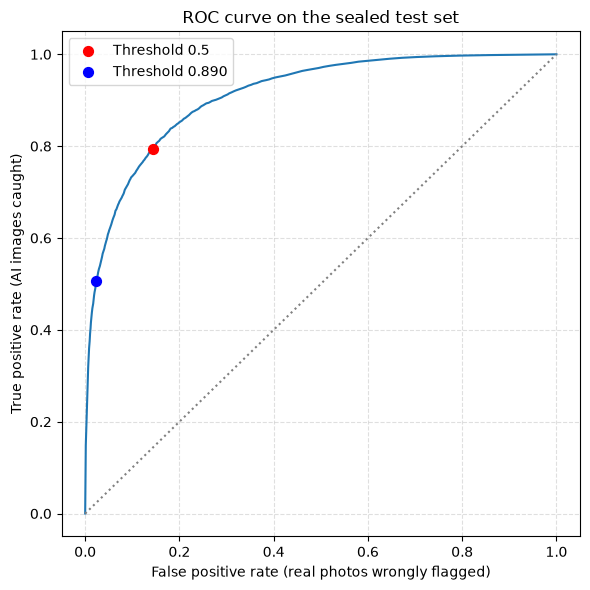

In [38]:
# thresholds and positions in the threshold array
idx_05 = np.argmin(np.abs(thresholds - 0.5))
idx_0890 = np.argmin(np.abs(thresholds - chosen_threshold))

plt.figure(figsize=(6,6))
plt.plot(fprs, tprs)
plt.plot([0, 1], [0, 1], linestyle=':', color='grey') # random guessing

# Mark the threshold points
plt.scatter(fprs[idx_05], tprs[idx_05], color='red', s=50, zorder=5, label='Threshold 0.5')
plt.scatter(fprs[idx_0890], tprs[idx_0890], color='blue', s=50, zorder=5, label='Threshold 0.890')

plt.xlabel("False positive rate (real photos wrongly flagged)")
plt.ylabel("True positive rate (AI images caught)")
plt.title("ROC curve on the sealed test set")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

<b>Figure 7 - ROC curve on the sealed test set. Shows true positive rate (AI images caught) against false positive rate (photos wrongly flagged as AI).</b>

### The ROC Curve explained

Initially the curve rises very steeply at first, before flattening significantly. This steep initial climb suggests that AI Image detection can increase rapidly at low false positive rates until around 0.15 where the curve bends and past that the model makes false accusations about real images being fake with little extra detection.

The AUC is 0.911, which is clear of the diagonal of 0.5. AUC measures how well the model ranks predictions and a score of 0.911 means that, given one randomly chosen AI image and one randomly chosen real photograph, the model scores the AI image higher 91.1% of the time.

The dots along the curve show the varying thresholds at 0.5 and 0.890 - threshold 0.5 sits high, but has 14% false accusations, whereas blue sits low but under 5%. During validation the threshold measured 0.5835, but on the graph this appears to be closer to 0.5, which could be down to validation being more optimistic about results than when it comes to running the final test.

In [39]:
# Count the four outcomes twice from the same predictions, but using the different thresholds
# test_scores doesn't change
cm_default = confusion_matrix(y_test, test_scores, threshold=0.5)
cm_strict  = confusion_matrix(y_test, test_scores, threshold=chosen_threshold)

# Display each as a lableled confusion matrix
show_confusion_matrix(cm_default, "At threshold 0.5 (reported default)")
show_confusion_matrix(cm_strict,  f"At threshold {chosen_threshold:.3f} (5% target)")

# False positive rate set to roughly 1%
idx = np.argmin(np.abs(fprs - 0.01))
print(f"At {fprs[idx]:.4f} false positive rate, {tprs[idx]:.4f} of AI images are caught")

**At threshold 0.5 (reported default)**

| | Predicted REAL | Predicted FAKE |
|---|---|---|
| **Actually REAL** | 8,571 | 1,429 |
| **Actually FAKE** | 2,059 | 7,941 |

**At threshold 0.890 (5% target)**

| | Predicted REAL | Predicted FAKE |
|---|---|---|
| **Actually REAL** | 9,763 | 237 |
| **Actually FAKE** | 4,934 | 5,066 |

At 0.0104 false positive rate, 0.3919 of AI images are caught


<b>Figure 8 - Stacked Confusion Matrices for threshold 0.5 and threshold 0.890. The last line reports on moving the threshold so that the there is a 1% false positive rate.</b>

The confusion matrices above tell an interesting story: 

> <h3>Moving the threshold from 0.5 to 0.890 avoids 1,192 wrong accusations (1,429 down to 237), at the cost of 2,875 additional undetected AI images (2,059 up to 4,934). Each wrong accusation avoided therefore costs roughly 2.4 AI images going undetected (2,875 / 1,192 ≈ 2.4).</h3>


The threshold on the test set was intended to be 5%, but the actual result was 2.37% (237 / 10000), which was stricter than intended. On the validation set it was 4.77%. Overall, the score distribution shifted slightly between the two sets so a threshold chosen on one didn't land the same on the other set. I would view this as a limitation of trying to pick thresholds in this way.

Raising the threshold did substantially reduce the false positive rate, from 14.3% to 2.4%. What no threshold can do is reduce both error types at once - every gain on one side is paid for on the other. That is a limit of the model's ranking ability rather than of where the line is drawn and only a better model would improve both. For that reason the threshold used for every figure reported in this project, so results stay comparable across sections 5 to 8.

The last line in this figure returns to something I wrote about in Section 2. I argued that false accusations are the serious error and the ROC curve would allow me to ask what a stricter setting would cost. So here I've found the point on the curve closest to 1% false accusations and the AI-image detection rate.

> At 0.0104 false positive rate, 0.3919 of AI images are caught

Pushing the false-accusation rate down to 1% drops detection to 39.2% — fewer than two in five AI images caught. There is no setting at which this model does well on both counts, which reinforces that the constraint is the model's ranking ability rather than the choice of threshold.

<b>One clarification is worth making here. Two confusion matrices are reported on the test set, but the test set was only used once. A single predict call produced 20,000 scores, and those same scores are read at two different thresholds. No model was retrained and no configuration was reselected on the basis of test performance, which would have been the leakage this project has guarded against in previous sections.</b>

---

## The most confident mistakes

One question I have going into this final part of Section 7 is which images did the model get wrong while being most certain about it?

Below is an interesting qualitative insight into the kinds of images the model was most confident of being AI-genereated and real, but were actually the opposite.

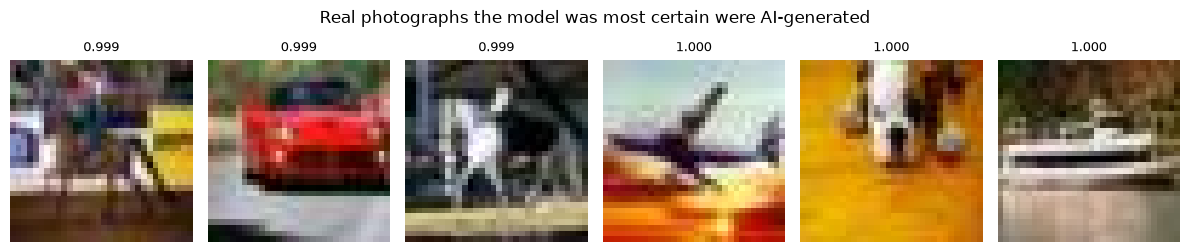

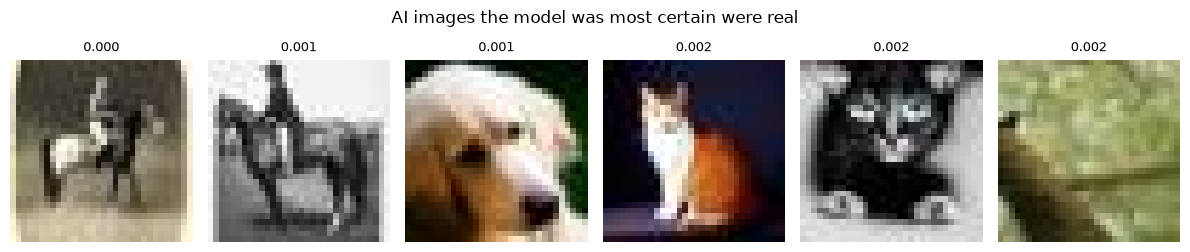

In [40]:
# 7.6 - THE MOST CONFIDENT MISTAKES.
# It adds a qualitative observation that supports Section 8's argument, nothing more.
# Which images did the model get wrong while being most certain about it?
scores = test_scores.ravel()

real_idx = np.flatnonzero(y_test == 0) # positions of all real images
fake_idx = np.flatnonzero(y_test == 1) # positions of all fake images

# scores[real_idx] - pulls out the just the scores belonging to real images
# np.argsort() - sorts the scores but this returns positions within that subset not the full test set
# real_idx[][:6] - use those subset positions to look up the real positions - then take the last 6 (highest)
# worst_fp = (real images the model scored highest)
worst_fp = real_idx[np.argsort(scores[real_idx])[-6:]]

# same for false negatives (fake images the model scored lowest)
# takes the first six (lowest)
worst_fn = fake_idx[np.argsort(scores[fake_idx])[:6]]

def show_image_grid(indices, title):
    # Space for a grid of 6 images
    fig, axes = plt.subplots(1, 6, figsize=(12, 2.6))

    # For each image.
    # zip(axes,indices) to pair each subplot with one image
    for ax, i in zip(axes, indices):
        ax.imshow(test_images[i]) # Show the image
        ax.set_title(f"{scores[i]:.3f}", fontsize=9)
        ax.axis("off")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

# show the image grids
# Showing images here is fine. The instructions say no exploratory visualisation at
# the START of a report, not the use of images to interpret results.
show_image_grid(worst_fp, "Real photographs the model was most certain were AI-generated")
show_image_grid(worst_fn, "AI images the model was most certain were real")

<b>Figure 9 - Comparing the model's most confident mistakes. The first row showcases real photographs the model was most certain were AI-generated. The bottom row showcases AI images the model was most certain were real.</b>

### What the images show?

The images are displayed with their corresponding confidence score above them.

The real photographs that the model was most certain were AI-generated seem to have quite rich environments in their backgrounds. The first 4 images of an equestrian, sports car, another equestrian and plane seem to feel quite visually rich. Lots of colours popping and visually contrasting with each other. It could be that the high detail and visual differences in areas between subject and background meant the model was more confident this was AI-generated. Looking at the images, I couldn't say explicitly what would have made them AI-generated and they look quite normal.

In contrast, I find the second group the most interesting overall. The AI images the model was most certain were real look to be more 'bland' for lack of a better word - they lack the colour richness. The images though most certainly look realistic (despite the pixelation) similar to the images above.  This is probably the most telling of the batch. They do look legitimately on the surface to be real images, but there is something that seems almost uncanny about them and 'odd'. Other than this though, I'm not certain what features would class it as AI-generated so perhaps the model was detecting something more granular in the images.

### What this means for Section 8 and Tying it back to my Hypotheses?

The false positives are colour-rich and the false negatives appear muted in comparison. If the model is keying on colour statistics, then it is using a global property of the image rather than fine pixel detail.

For Hypothesis 3 and looking at these images, this means greyscale should hurt more than H3 expects. In hypothesis 3 I said removing colour would cost little, but these images suggest otherwise, which is why Section 8's transformation experiment will confirm this or contradict the hypothesis. 

For Section 8, I intended to split images into two families: Family A includes transformations that destroy fine pixel detail and Family B includes transformations that preserve fine detail but change something else.

Brightness and contrast both change colour statistics and  are family B transformations, and I predicted that this would not matter as much as the invisible details or the "generator fingerprints". From these observations, those transformations might hurt after all. That would not falsify Hypothesis 2, but it would mean the two families are less cleanly separated than the design assumes, and a Family B result could not be read as pure evidence either way.

Another factor to consider is that the muted look of the AI images could be a property of how CIFAKE was built, considering that the Stable Diffusion output is downsampled to 32x32, which doesn't have anything to do with the properties of synthetic imagery in general. This was a point I raised in section 1.

---

# Section 8 — The transformation study

This section sits outside of the seven section workflow. This is an additional investigation with the aim of answering Hypotheses 2 and 3.

### To recap here they are:

> <b>H2. This is the central hypothesis.</b> Transformations that destroy fine pixel detail will cost far more accuracy than transformations that preserve it. That differential pattern would be consistent with reliance on generator-specific artefacts rather than on anything semantic. In plain terms, as fine pixel-level details are stripped out and images are degraded in different ways, then the accuracy for deciding between real and fake image should drop a lot, therefore telling us what the model was actually using to tell real from fake. It shows the model was relying on fine, invisible detail (the "generator fingerprint"), and not on anything meaningful about the image's content. In the event that accuracy barely changes, that suggests it's picking up on real semantic cues instead. This hypothesis introduces an experiment that is made up of three parts:


> * Baseline — clean images, giving the reference accuracy.
> * Treatment - Family A, transformations that destroy fine pixel detail.
> * Control — Family B, transformations that preserve fine detail but change something else.

> <b>H3. Greyscale conversion costs comparatively little, because signals that hint at real or fake are textural rather than chromatic.</b> The hypothesis here is that removing colour shouldn't affect accuracy much, because we are still preserving fine texture and pixel-level detail. Should accuracy hold up, then this is consistent with hypothesis 2. With greyscale conversion we are testing colour versus luminance texture. The conversion preserves spatial detail while removing chromatic detail.

The core work of this section is the believed premise that generator fingerprints live in fine pixel-level detail and that the semantic content (which is what the image is actually about) will survive mild image processing.

---

## How will I investigate the research question in Section 8?

The experiment concerns itself with two families of transformation, each expected to make opposite predictions:

**Family A — destroys fine pixel detail.** Predicted to hurt badly.

- JPEG recompression at quality 95, 75, 50, 25
- Downsample to 16×16 and 8×8, then stretch back to 32×32
- Gaussian blur at radius 1.0
- Additive noise at sigma of 10.

The JPEG and downsampling at several strengths rather than one allows me to plot a curve and identify a relationship. If accuracy falls further as more detail is destroyed, this is stronger evidence than a single before-and-after comparison.

**Family B — preserves fine detail, changes global appearance.** Predicted to barely matter.

- Horizontal flip — the cleanest control, since every local texture survives exactly but every
  input position changes
- Brightness shift (x1.3)
- Contrast change (x1.5)

**Colour.** This is a separate axis testing Hypothesis 3. I'll perform greyscale conversion, which removes chromatic information and preserves spatial detail. The input will remain at 3072 values per image so the trained model can still accept it.


**Composite.** Downsample x2, then JPEG to a quality of 50, then a small brightness shift — imitating an image being
screenshotted and reposted.


## Important points about how this experiment is run:

* The transformation is applied to the sealed test set only.
* The three final models from Sections 6 and 7 are already trained on clean images, so no retraining is involved.
* Each transformation costs only the time to transform images and run predict.
* Every figure is reported as the mean across the three seeds, with the spread shown as before.

One key question will be answered here:

> ### Is my deployed detector fragile to image transformation?

If someone is using instagram filters, or screenshotting and manipulating images and then passing into my detector, can it still tell if an image was AI-generated?

## Making this experiment better.

A future experiment would involve retraining on transformed images to ask whether the information survives at all. I won't be running this here, but talk about this in Section 9. If accuracy drops under a transformation, this design cannot tell whether the information has genuinely been destroyed or whether the model simply was never trained to read it in that form. Separating those two explanations would require retraining on transformed images, which is named as future work in section 9.

In [41]:
# 8.1 - THE TRANSFORMATION FUNCTIONS.
# Original code - IC
# Every function takes uint8 images of shape (N, 32, 32, 3) and returns the same
# shape, so the output goes straight into flatten_and_scale().

from PIL import Image, ImageFilter
import io

# FAMILY B and colour: pure NumPy, given in full

# Flips the image horizontall from left to right
def horizontal_flip(images):
    """Mirror left to right. Local textures survive exactly; every position moves."""
    # Use an array slice along the width axis (N, 32, 32(width), 3) (Batch size, Height, Width, Channels) (rank-4 tensor)
    # Reverses the order of columns while keeping row heights and colour channels the same
    # array slicing syntax [start:stop:step] -> [::-1] Just traverse array in reverse order
    return images[:, :, ::-1, :]


# Image can be made lighter or darker
def brightness(images, factor=1.3):
    """Scale brightness. Above 1 brightens, below 1 darkens."""
    # Converts every pixel to floats
    # Multiplies every pixel by a multiplier - caps values between 0 and 255
    # Converts back to standard integers
    return np.clip(images.astype(float) * factor, 0, 255).astype(np.uint8)

# Increase or decrease the separation between dark and light areas around mid-grey
def contrast(images, factor=1.5):
    """Stretch or compress contrast around mid-grey (128)."""
    # Scales pixel values away from 128. Clips the output to 0-255.
    # Converts to float -> performs operation and then converts back to integer
    return np.clip((images.astype(float) - 128.0) * factor + 128.0, 0, 255).astype(np.uint8)

# Adds a standard gaussian noise to simulate image graininess or sensor noise.
def add_noise(images, sigma=10.0, seed=0):
    """Add Gaussian noise and clip back into range."""
    rng = np.random.default_rng(seed) # Generate random normal distribution values
    noisy = images.astype(float) + rng.normal(0, sigma, images.shape) # Add these values to each pixel
    return np.clip(noisy, 0, 255).astype(np.uint8)

# Converting the color image to black and white while retaining a 3 RGB structure
# Will still work with the trained model
def greyscale(images):
    """Remove colour but KEEP the 3-channel shape.

    The models expect 3,072 inputs. One channel would give 1,024 and be rejected.
    So convert to luminance, then stack three identical copies: colour is gone,
    shape is unchanged.
    """
    # Calculating luminance (the greyscale value)
    # Green is perceived more by the human eye so different factors to create a single-channel brighness value for every pixel.
    lum = (0.299 * images[..., 0] + 0.587 * images[..., 1] + 0.114 * images[..., 2])
    # np.stack takes three copies of the luminance array and combines them along the last axis.
    # R = G = B, so image looks grayscale but the shape remains 3-channel and 3072 inputs
    return np.clip(np.stack([lum, lum, lum], axis=-1), 0, 255).astype(np.uint8)


# FAMILY A: these three need PIL, so they share one loop pattern 
# Each converts an image to a PIL object, does something, converts back:

def gaussian_blur(images, radius=1.0):
    """Blur each image."""
    # Loop through each numpy array image
    # Convert the numpy array img into a PIL image object
    # Applies PIL's Gausssian Blur
    # Ensures image is in 3 channel RGB and converts back into a numpy array with integer pixel values
    out = []
    for img in images:
        pil = Image.fromarray(img).filter(ImageFilter.GaussianBlur(radius))
        out.append(np.asarray(pil.convert("RGB"), dtype=np.uint8))
    # Stacks the list of numpy array images back into a single 4D array
    return np.stack(out)


def downsample(images, factor=2):
    """Shrink then stretch back to 32x32. Detail is destroyed permanently."""    
    # Loop through each numpy array image
    out = []
    small = 32 // factor # New dimension of the image
    for img in images:
        # Resize the image
        pil = Image.fromarray(img).resize((small, small)).resize((32, 32))
        out.append(np.asarray(pil.convert("RGB"), dtype=np.uint8))
    return np.stack(out)
    

# JPEG Compression - quality parameter to specify
def jpeg_recompress(images, quality=50):
    """Save as JPEG at the given quality, then reload. The saving is what damages it."""
    out = []
    for img in images:
        # Converts the raw image array into a PIL image object
        pil = Image.fromarray(img)
        # Write to an in-memory file instead of resizing (quicker than slow disk read/write operations)
        buf = io.BytesIO()
        # Encode image using JPEG compression
        pil.save(buf, format="JPEG", quality=quality)
        buf.seek(0)
        # Reads and decodes the JPEG image out of the memory
        pil = Image.open(buf)
        out.append(np.asarray(pil.convert("RGB"), dtype=np.uint8))
    return np.stack(out)


# COMPOSITE: chains three of the above

def screenshot_repost(images):
    """Imitate an image being screenshotted and reposted:
    downsample x2, then JPEG at quality 50, then a small brightness lift."""
    # Three calls in sequence with each one feeding the next
    images = downsample(images, factor=2)
    images = jpeg_recompress(images, quality=50)
    images = brightness(images, factor=1.1)
    return images

In [42]:
# The transformations dictionary
TRANSFORMS = {
    "clean":            lambda im: im,

    # Family A - destroys fine pixel detail
    "JPEG q95":         lambda im: jpeg_recompress(im, quality=95),
    "JPEG q75":         lambda im: jpeg_recompress(im, quality=75),
    "JPEG q50":         lambda im: jpeg_recompress(im, quality=50),
    "JPEG q25":         lambda im: jpeg_recompress(im, quality=25),
    "downsample x2":    lambda im: downsample(im, factor=2),
    "downsample x4":    lambda im: downsample(im, factor=4),
    "blur r=1.0":       lambda im: gaussian_blur(im, radius=1.0),
    "noise s=10":       lambda im: add_noise(im, sigma=10),

    # Family B - preserves fine detail, changes global appearance
    "flip":             horizontal_flip,
    "brightness 1.3":   lambda im: brightness(im, factor=1.3),
    "contrast 1.5":     lambda im: contrast(im, factor=1.5),

    # Colour axis (H3)
    "greyscale":        greyscale,

    # Composite
    "screenshot":       screenshot_repost,
}

FAMILY = {
    "clean": "baseline",
    "JPEG q95": "A", "JPEG q75": "A", "JPEG q50": "A", "JPEG q25": "A",
    "downsample x2": "A", "downsample x4": "A",
    "blur r=1.0": "A", "noise s=10": "A",
    "flip": "B", "brightness 1.3": "B", "contrast 1.5": "B",
    "greyscale": "colour",
    "screenshot": "composite",
}

means match      : True
arrays identical : False


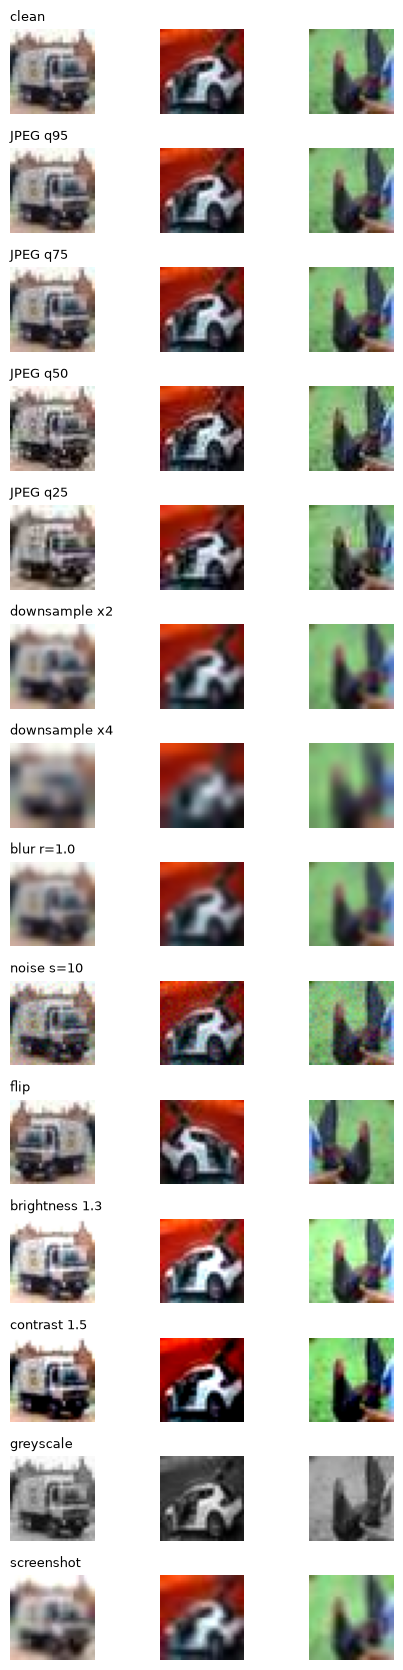

In [43]:
# 8.2 - CHECK THE TRANSFORMATIONS DO WHAT THEY CLAIM.
# Five minutes here prevents an invalid section.

# Numeric check on the flip: same pixel values, different arrangement.
flipped = horizontal_flip(test_images)
print("means match      :", np.allclose(test_images.mean(), flipped.mean()))   # expect True
print("arrays identical :", np.array_equal(test_images, flipped))              # expect False


# Show the first 3 test images through every transformation as a grid,
# one row per transformation with the originals in the top row.

n_rows = len(TRANSFORMS) # the length of the entire transformations

# Create all of the image plots
fig, axes = plt.subplots(n_rows, 3, figsize=(5, 1.2 * n_rows))
for row, (name, fn) in enumerate(TRANSFORMS.items()):
    out = fn(test_images[:3]) # Transforms 3 images from the test set
    for col in range(3):
        axes[row][col].imshow(out[col]) # row is the transformation, col is the image
        axes[row][col].axis("off")
    axes[row][0].set_title(name, fontsize=9, loc="left") # label on the left most image of each row

fig.tight_layout()
plt.show()

<b>Figure 10 - Showcasing all of the Family A and Family B image transformations performed on a series of three images from the test set.</b>

In [44]:
# 8.3 - ARM 1: train on clean, test on transformed.
# No retraining. The three final models already exist - only the test set changes.
arm1_results = []

for name, fn in TRANSFORMS.items():
    t0 = time.time()
    print(name, end=" ... ", flush=True)

    x_t = flatten_and_scale(fn(test_images)) # transform then flatten and scale

    # Make a predict with each of the three final_models
    # Then collect the accuracy and aucs into two lists
    accs, aucs = [], []
    for model in final_models:
        s = model.predict(x_t, verbose=0)
        accs.append(accuracy(y_test, s))
        aucs.append(roc_auc(y_test, s))


    # append a dict with these keys so print_results_table works
    arm1_results.append({
        "label": name,
        "params": final_models[0].count_params(),
        "acc_mean": float(np.mean(accs)),
        "acc_std": float(np.std(accs, ddof=1)),
        "auc_mean": float(np.mean(aucs)),
        "auc_std": float(np.std(aucs, ddof=1)),
        "turn_epochs": [FINAL_EPOCHS],
        "family": FAMILY[name]
    })

    print(f"{time.time() - t0:.0f}s")

# arm_1_results saving to json
if arm1_results:
    with open("arm1_results.json", "w") as f:
        json.dump(arm1_results, f, indent=2)
    print(f"\nSaved {len(arm1_results)} transformations to arm1_results.json")

clean ... 2s
JPEG q95 ... 3s
JPEG q75 ... 2s
JPEG q50 ... 2s
JPEG q25 ... 2s
downsample x2 ... 2s
downsample x4 ... 2s
blur r=1.0 ... 2s
noise s=10 ... 2s
flip ... 2s
brightness 1.3 ... 2s
contrast 1.5 ... 2s
greyscale ... 2s
screenshot ... 3s

Saved 14 transformations to arm1_results.json


| Config | Params | Val accuracy | AUC | Turn epoch |
|---|---|---|---|---|
| clean | 1,836,545 | 0.8163 ± 0.0082 | 0.9117 ± 0.0010 | 23.0 |
| JPEG q95 | 1,836,545 | 0.8153 ± 0.0085 | 0.9110 ± 0.0010 | 23.0 |
| JPEG q75 | 1,836,545 | 0.8154 ± 0.0088 | 0.9111 ± 0.0010 | 23.0 |
| JPEG q50 | 1,836,545 | 0.8111 ± 0.0080 | 0.9069 ± 0.0013 | 23.0 |
| JPEG q25 | 1,836,545 | 0.8087 ± 0.0088 | 0.9056 ± 0.0011 | 23.0 |
| downsample x2 | 1,836,545 | 0.7892 ± 0.0300 | 0.9005 ± 0.0018 | 23.0 |
| downsample x4 | 1,836,545 | 0.7124 ± 0.0551 | 0.8662 ± 0.0040 | 23.0 |
| blur r=1.0 | 1,836,545 | 0.7696 ± 0.0442 | 0.8957 ± 0.0027 | 23.0 |
| noise s=10 | 1,836,545 | 0.8146 ± 0.0102 | 0.9099 ± 0.0014 | 23.0 |
| flip | 1,836,545 | 0.8078 ± 0.0082 | 0.9026 ± 0.0003 | 23.0 |
| brightness 1.3 | 1,836,545 | 0.8134 ± 0.0071 | 0.9094 ± 0.0016 | 23.0 |
| contrast 1.5 | 1,836,545 | 0.7676 ± 0.0253 | 0.8649 ± 0.0098 | 23.0 |
| greyscale | 1,836,545 | 0.7423 ± 0.0352 | 0.8533 ± 0.0082 | 23.0 |
| screenshot | 1,836,545 | 0.7880 ± 0.0310 | 0.8984 ± 0.0020 | 23.0 |


Best by validation accuracy: clean (0.8163 ± 0.0082)
Within one standard deviation: JPEG q75, JPEG q95, noise s=10, brightness 1.3, JPEG q50, JPEG q25
These cannot be separated from clean by this measure.

Best by AUC: clean (0.9117 ± 0.0010)
Within one standard deviation: JPEG q75, JPEG q95
These cannot be separated from clean by this measure.


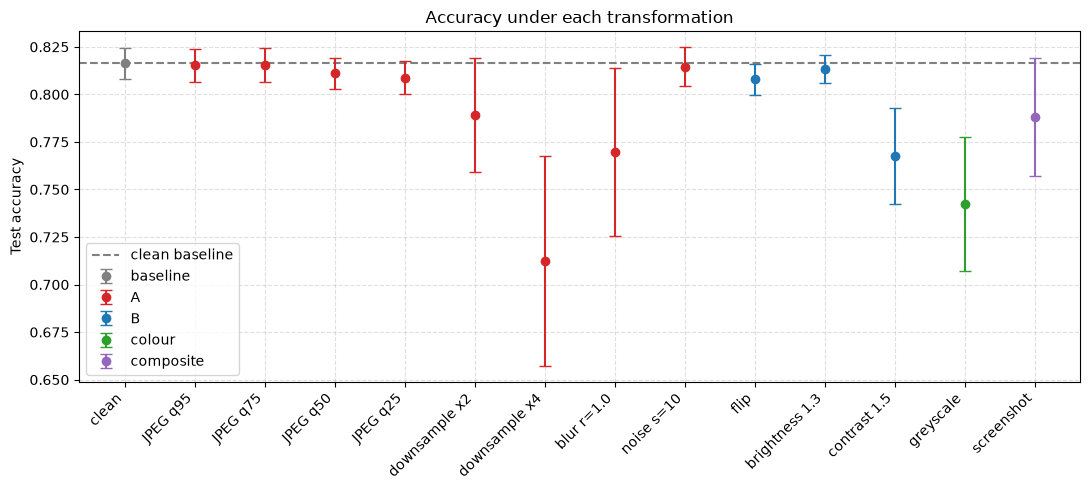

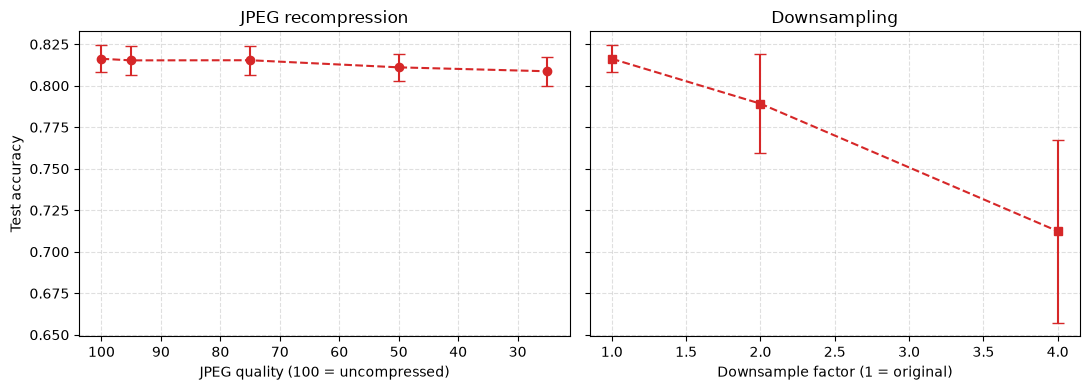

In [45]:
# 8.4 - ARM 1: table and the signature figure.

# guard so a full Restart & Run All does not crash before Arm 1 has been written
if arm1_results:
    print_results_table(arm1_results)


colours = {"baseline": "grey",
           "A": "tab:red",
           "B": "tab:blue",
           "colour": "tab:green",
           "composite": "tab:purple"}

# Figure - The signature curve.
# Has accuracy on the y-axis, one point per transformation
# Error bars from the three seeds, and a dashed horizontal line at the "clean accuracy"

# What will this figure tell someone: do the family A points sit clearly below the dashed line while
# the family B points sit on it?

# the baseline value for the dashed line
clean_acc = next(r["acc_mean"] for r in arm1_results if r["label"] == "clean")

# labels for each results
labels = [r["label"] for r in arm1_results]
xs = np.arange(len(arm1_results))


plt.figure(figsize=(11, 5))
# Plot a horizontal line
plt.axhline(clean_acc, linestyle="--", color="grey", label="clean baseline")


# plot one errorbar call per family, so the legend has 5 entries not 14
for fam, colour in colours.items():
    idx = [i for i, r in enumerate(arm1_results) if r["family"] == fam]
    if not idx:
        continue
    # Draws error bars for mean accuracy, mean std
    plt.errorbar([xs[i] for i in idx],
                 [arm1_results[i]["acc_mean"] for i in idx],
                 yerr=[arm1_results[i]["acc_std"] for i in idx],
                 fmt="o", capsize=4, color=colour, label=fam)
    
# Draw the plot
plt.xticks(xs, labels, rotation=45, ha="right")
plt.ylabel("Test accuracy")
plt.title("Accuracy under each transformation")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# Figure - the dose-response curve
# Plot accuracy against JPEG quality (95, 75, 50 ,25) as a line
# Also accuracy against the downsample factor (1, 2, 4)

# If the accuracy falls steadily as detail is destroyed, that gradient
# is stronger evidence for H2 than any single comparison

# Two plots sharing same y-axis
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

def get(label):
    r = next(r for r in arm1_results if r["label"] == label)
    return r["acc_mean"], r["acc_std"]

# JPEG Figure - treat "clean" as quality 100 (uncompressed)
jpeg = ["clean", "JPEG q95", "JPEG q75", "JPEG q50", "JPEG q25"]
ax1.errorbar([100, 95, 75, 50 ,25],
             [get(l)[0] for l in jpeg],
             yerr=[get(l)[1] for l in jpeg],
             fmt="o--", capsize=4, color="tab:red")
ax1.invert_xaxis()
ax1.set_xlabel("JPEG quality (100 = uncompressed)")
ax1.set_ylabel("Test accuracy")
ax1.set_title("JPEG recompression")

# Downsampling - treat "clean" as factor 1
ds = ["clean", "downsample x2", "downsample x4"]
ax2.errorbar([1, 2, 4],
             [get(l)[0] for l in ds],
             yerr=[get(l)[1] for l in ds],
             fmt="s--", capsize=4, color="tab:red")
ax2.set_xlabel("Downsample factor (1 = original)")
ax2.set_title("Downsampling")

for ax in (ax1, ax2):
    ax.grid(True, linestyle="--", alpha=0.4)

fig.tight_layout()
plt.show()
    

<b>Figure 11 - The accuracy and AUC across the Family A and B transformations. </b>
<br>
<b>Figure 12 - The error bars for Accuracy under each transformation, JPEG recompression and Downsampling (which contain multiple runs at different variations).</b>

## Evaluation of Section 8

This section splits transformations into two families: a family A and family B. These are compared against a baseline, which was the final results from the end of section 7.

Family A's transformations destroy fine pixel detail. Here that's:
* Downsample x2 and x4
* JPEG q25, q50, q75 and q95
* Blur r=1.0
* Noise

Family B's transformations preserve fine detail but change something else. Here that's:
* Contrast 1.5
* Flip
* Brightness

A colour-axis - greyscale transformation (separate from both families).

One additional screenshot transformation was applied (applying various transformations like a real world scenario).


## How Family A and Family B results differed:

Family A's transformation results are split down the middle. Downsampling and blurring had the worst accuracy drop of -10.4 and -4.7 respectively. The other two Family A transformations, JPEG and noise performed much better only dropping under 1 accuracy point at any strength.

Family B's transformations vary also. Contrast 1.5 performed worse than five of the eight family A transformations, at -4.9 pts. Flip and Brightness performed much better at -0.85pts and -0.3pts respectively. 


The most damaging transformations remove some kind of information that the model is using to infer the image is AI-generated: 

> Downsample and Blur (Family A) performed comparatively worse than the rest of the family A transformations. They remove spatial information from the images.

> Greyscale and contrast (Colour-axis and Family B) remove chromatic information.

Removing spatial and chromatic information seemingly makes it harder for the model to pick out signatures within the images pre-transformation.

The harmless transformations were:

> JPEG, noise - These added perturbations without removing much.
> Flip and brightness - These transformations rearranged/rescaled, which didn't destroy anything.

Flip in particular was an interesting transformation with an accuracy of -0.85 from the standard set in Section 7. Every input value changed position, but every local texture remained and the model barely noticed. The model was able to learn something position-independent despite having no architectural help. 

The dose-response curves for JPEG compression and downsampling are different in structure. Downsampling gives a negative gradient at each increment, whereas JPEG is flat from 95 to 25. This could be due to the fact that the input images are so small (32 x 32 images), which makes it difficult to distinguish detail - an aggressive JPEG compression removes little of what was already there, making this seem like a null result.


## So what conclusions can be drawn here? How does this affect H2 and H3?

> ### The dividing line from these is not fine detail versus global appearance. The transformations can be split instead like this: removing information versus perturbing information. 

My Hypothesis 2 predicted that removing fine details would hurt the model's accuracy and suggested that the model would be picking up on real semantic cues and generator fingerprints within the image. The results show this is just not the case and hypothesis 2 isn't supported as I've stated. 

The separation instead comes from broad image characteristics that the model is able to pick up such as colour distribution and coarse structure, rather than the fine-grained artefacts within the images. 

The most critical transformation here to support hypothesis 2 (being downsample and blur) that destroyed fine pixel detail were amongst the worst performers for the model. If hypothesis 2 held, every Family A transformation should have damaged accuracy, since all of them destroy fine pixel detail. Downsampling and blurring did. JPEG recompression and additive noise did not, at any strength - and those two should have been the most destructive to a high frequency generator fingerprint of the kind Frank et al. (2020) describe. The only caveat to their work was that it was on GANs and CIFAKE uses images produced with a diffusion model. Nevertheless, the family label therefore fails to predict the outcome, which is what undermines hypothesis 2.

Figure 12 above shows how downsampling factor affected accuracy on the test set, and it's a clear observation - downsampling in particular removes detail and the increase from 1.0 to 4.0 is a 10.4 accuracy drop with the spread widening (showed by the error bars) and AUC decreasing from 0.9117 to 0.8662. The drop in AUC means the model got worse at ranking fakes above reals. One thing to note here is the downsampling x4 value clears the linear baseline by a smaller margin than the 16 points from earlier (only 5.6 points clear here).

The greyscale transformation dropped accuracy by 7.4 points from the baseline, which is the second largest drop of anything tested. This contrasts with what I said would happen in hypothesis 3. In section 7.6, I observed that real images from the set contained more colour than the AI-generated images which seemed to be more muted and less colourful. Colour-rich false positives and muted false negatives suggested that the greyscale would hurt more than H3 expected - my thinking was confirmed here in this experiment with the greyscale transformation.

In Section 7.6 I also predicted that brightness and contrast might complicate the family split because they both alter colour statistics. Contrast dropped accuracy by 4.9 points and brightness dropped 0.3. The one that compresses the colour space hurt; the one that shifted the colour space didn't.

> ### The result of section 8 is consistent with the detector using global appearance statistics (particularly colour) instead of generator-specific signatures.

In Section 1, I remarked how the CIFAR-10 photographs and downsampled Stable Diffusion output would differ in some visual way (including colour character) and the model keyed on that would be exactly what was created here.

---

# Section 9  - Conclusion and Closing Thoughts

## Research Question Conclusions and Final Thoughts

> The research question posed was quite simple. Do AI detectors learn general features of synthetic imagery or are they looking at generator-specific artefacts?
> 
> I am of the opinion that to be truly useful, an experiment such as this must test detectors against real-world phenomena and cultural events rather than idealised lab conditions. For the constraints of my project, I used a pre-constructed CIFAKE dataset with real and AI-generated images of rather arbitrary choice in terms of their subject matter, but I feel the result would have been far more intriguing with a set of images from popular social media sites or other heavily used internet domains. Essentially, images that people will actually see, and have the potential to wrongly classify in their heads as REAL or AI-generated. My research question is therefore more culturally relevant than ever. At the time of this paper's writing, image generators have made significant advancements over the Stable Diffusion 1.4 model that produced the images for this dataset. Their work circulates heavily on the internet and higher quality images look practically indistinguishable to the human eye.
>
> The results from the research suggests that the trained model architecture was more effective at using global appearance statistics (in particular colour) instead of generator-specific artefacts. The evidence here suggests that this model did not rely on such fingerprints, rather than that they are absent. A multilayer perceptron operating on flattened 32x32 pixels may simply lack the machinery to exploit frequency domain artefacts, even where they are present.
>
> This could be down to the overall complexity of the model; the final architecture uses Dense layers and is not 'deep' by any means, in comparison to the convolutional network used by Bird and Lotfi. 
>
> I constructed a multilayer perceptron model inspired by the work of Bird and Lotfi (2024) and used the CIFAKE dataset. The model had some success at classifying AI and real images but research became more interesting after testing the model on transformed images. 
>
> Transformations here represent what is possible with current photo-editing applications and social media filters - they can manipulate images and change the aesthetic to the human eye, but for an AI model can it still detect fine-level details within an image that signal it's real or fake?
>
> The results were mixed and support my conclusion that the model used global appearance statistics rather than fine-detail. My model performed well on transformations that perturbed visual information (JPEG compression, brightness, flip and additive noise) and not transformations that removed information. One of my initial assumptions was that the semantic content (meaning what the picture is actually supposed to depict) of an image is quite robust to image processing and changes, but the most damaging transformations here removed spatial and chromatic information from the images.

## The verdict on each hypothesis

> In my research question I made three hypotheses and I investigated each one over the course of this research paper. Here is my verdict on each one.
>
> ### Hypothesis 1
> In Section 5, I tested the dense network against two baselines: a coin flip and a logistic regression model. Logistic regression only draws straight lines and the premise was that the difference between a real and fake image cannot be separated with a straight line because there are far more intricate details. The initial model constructed at the end of Section 5 beat both baselines with a 3.4 point gap over the regression model, but not by a significant amount that the hypothesis had suggested. By the end of section 6 however, the accuracy gap over logistic regression had grown to 14.7 points as the model architecture grew. I revisited this hypothesis at the end of Section 6 and concluded that the hypothesis was more strongly supported with the results due to the improved model. The work in section 7 only strengthened this. Initially my evidence only weakly supported the hypothesis and begged the question that the overall architecture was inadequate, requiring a higher capacity which included more layers and units, this was why the fine tuning of the model in Section 6 and 7 was important.
>
> ### Hypothesis 2
> The central hypothesis of my research question: will the transformations that destroy fine pixel detail cost far more accuracy than transformations that preserve it, meaning a reliance on generator-specific artefacts rather than on anything semantic. The simple answer is that H2 isn't supported. In section 4, I stated how I would not be augmenting (flipping, rotating, cropping, brightness, etc.) any images that would be used for training the model, as this would invalidate hypothesis 2 because I'd be training a model on already transformed images. But in section 8, the transformations were applied at test time and I split these transformations into two families. Family A included transformations that destroy fine pixel detail and Family B included transformations that preserve fine detail but change something else and it became clear at the end of section 8 that the model was relying on characteristics such as colour and spatial information rather than fingerprints that the generator had left behind. Downsampling, greyscale and contrast led to some of the highest drops in accuracy relative to the final model's 81.63% accuracy and each removed some kind of the information that model was using to infer an image was AI-generated. As stated above, not due to an absence of such fingerprints, but because this particular model didn't use them.
>
> ### Hypothesis 3
> The most interesting result comes from Hypothesis 3. H3 predicts that removing chromatic information costs comparatively little to accuracy since fine texture and pixel-level detail are preserved. The greyscale transformation's result in section 8 was the opposite of what H3 predicted and therefore disproving what I thought would be true. The images with the greyscale applied performed the second-worst overall of all the transformations at 0.7423 accuracy and an AUC of 0.8533, which was actually the lowest in the entire group. The AUC being the lowest here is significant, as it signals the model struggled to rank fake images above real ones the most when this transformation was applied.
> 
>  In hindsight, a warning sign to this result came at the end of section 7.6, where I displayed the model's most confident mistakes, which were essentially real photos it was confident were AI-generated and AI-generated photos it was sure were real images. The real photos displayed much more chromatic range, whereas the fake photos seemed much more mute with less visual depth to them. In 7.6, I noticed how the AI-generated images have an 'uncanny' look to them and lack the colour richness that the real photos had.

## The benchmark accuracy by Bird and Lotfi

>It was easy to compare the results of my model to the benchmark accuracy set by Bird and Lotfi, but it must be remembered that the fundamental architecture of their model was different to mine.
>
><b>In comparison, my final architecture is a multilayer perceptron constructed with a fully connected network with two hidden layers of 512 ReLU units and a single sigmoid output, trained with Adam at a learning rate of 0.0001 for 23 epochs (1,836,545 parameters).</b>
>
> The final model reached a test accuracy of 0.8163 ± 0.0082 and an AUC of 0.9117 ± 0.0010, averaged over three random seeds. Its best validation accuracy was 0.8226 ± 0.0078, so the drop on the unseen data was 0.0063 - which is smaller than the run-to-run spread, indicating that the selection process across Sections 6 and 7 did not meaningfully overfit the validation set.
>
>This sits 11.4 points below the 92.98% reported by Bird and Lotfi (2024). That gap is architectural rather than failure of the method used here: their model used convolutional layers, which encode the assumption that nearby pixels are related, while a multilayer perceptron on flattened pixels has no such prior and must discover any spatial structure from scratch.


## Why AUC earned its place after all

> I specified early in the report why AUC is an important measure, but after conducting sections this became apparent on three separate occasions. Accuracy measures decisions at a single threshold, while AUC measures how well the model ranks fakes above reals across every possible threshold (Fawcett, 2006).
>
> In section 6, the 3 x 512 configuration ranked second on accuracy but was the weakest of all the deep models on AUC and it only looked good because its threshold sat favourably. In section 7, L2 0.0001 appeared to change nothing on accuracy while producing the highest AUC recorded anywhere in the project. In both cases accuracy alone would have led to the wrong configuration.
>
> The third case bears directly on the hypotheses. Blur cost 4.7 accuracy points but only 1.6 points of AUC, meaning it shifted where the decision boundary fell more than it damaged the model's underlying ranking. Greyscale behaved differently: a 7.4 accuracy point drop and 5.8 for AUC, which was the lowest AUC of any condition tested. So greyscale did not merely move the threshold, but genuinely degraded the model's ability to separate a real image from a fake image. That distinction can only be made by including both measures. AUC overall was half as variable across seeds as accuracy which is why it gave deeper insight into configurations that accuracy could not. 


## The confound

> At the end of Section 1, I remarked how the two halves of the CIFAKE dataset go through different processing routes, so part of any measurable difference may reflect their processing history rather than synthesis of the image itself.
>
> The real half contains CIFAR-10 photographs and the fake half is Stable Diffusion 1.4 output rendered to 32 x 32, which are different production routes (Bird and Lotfi, 2024). I identified this confound at the outset but did not design around it and the results suggest it may be doing more work than anticipated. The evidence shows the model keys on colour and coarse structure, which are precisely the properties most likely to differ between two differently-produced image sets and what was visible in section 7.6 when looking at the most confident mistakes. An improvement to this limitation would have been identical preprocessing applied to both halves before training. 

## Limitations and How could I have improved the Deep Learning Workflow and the Model?

> The biggest improvement for my workflow was testing directly for generator fingerprints without abandoning the Dense-only constraint. Frank et al. (2020) identified generator artefacts in the frequency domain rather than the pixel domain. Using a discrete cosine transform applied in numpy before flattening would have fed frequency coefficients to the same architecture. This would have tested where the artefacts were present in a way that just reading the raw pixel values wouldn't be able to achieve by the network. I believe this change inspired by their findings would have altered the outcome the most and utilised no convolutional layers.
> 
> Other limitations I've identified within my workflow:
> * The AI-generated images are only from one generator - Stable Diffusion 1.4, which is from 2022. Image models have progressed in visual fidelity since then.
> * The 32x32 images are small enough that the frequency artefacts may not survive at all.
> * The one preprocessing pipeline.
> * The model utilises Dense Layers only, with no spatial priors (Chollet and Watson, 2026, p.155).
> * In retrospect, the three seeds is a thin basis for the variance estimates.
> * The lack of a second run in section 8 - retraining the model on transformed images would answer the questions posed by Hypothesis 2 and 3 more clearly since the results from Section 8 don't answer the question of whether the accuracy drops under a transformation because the information has genuinely been destroyed or because the model simply was never trained to read the images in that form.
> * The threshold was selected using a proxy model trained on 80,000 images rather than the final model itself, since the final model had seen the validation images during training. Because the proxy is trained on less data, its score distribution differs slightly from the final model's, which is why a threshold targeting a 5% false-positive rate produced 2.37% on the test set. A nested validation, holding out a further split purely for the threshold selection would have removed any mismatch.


## Future work

> The sequel to this experiment would involve multiple recently developed image generators in a cross-generator experiment. Wang et al ran a similar experiment across eleven generators in 2020, but this one would focus on more recent generators and models (Wang et al., 2020). It paves the way for a more interesting result, since the research question opens to more general AI-image detection and not just the signatures and fine pixel-level details of one slightly outdated image diffusion model. 
>
> On a more technical note, future work would include the expansion of the dataset to utilise higher quality images in an attempt to see if a model can detect signatures and generator fingerprints when there is more pixel information. This would significantly increase training times and processing, requiring more compute overall. Training on larger datasets would give the model more exposure to specific patterns and opening up to convolutional layers with added depth would make this a truly 'deep' model and increase the neural networks ability to classify real and AI-generated imagery.
>
> Mentioned already, the relevance of AI-generated media today and in the future poses a problem. How difficult will it be to discern what is real or fake? Think about the ramifications of the ability to use near-faultless AI-image generation models to spread fake photographs, news and potentially harmful media across the internet. Building a generalistic model that can alert people to whether an image or edited photo has been generated by AI would be an invaluable asset for the future.


> The research question shows the process of developing and fine-tuning a model to detect real and AI-generated images. This detector appears to rely on the global characteristics of an image (e.g. chromatic and spatial information) rather than generator-specific artefacts. I would like to stress that this is a finding about this model on this dataset, not about detection in general and the confound means it may partly reflect how CIFAKE was assembled. A detector keyed on broad colour statistics would fail on exactly the images that matter most: high quality output from newer generators that no longer looks muted.

---
## Code provenance

The table below records which code in this notebook is original and which was adapted from a source.

| Code | Source |
|---|---|
| `load_split`, `stratified_split`, `flatten_and_scale` | Original |
| `accuracy`, `roc_auc`, `error_breakdown` | Original, verified against hand-worked values |
| `confusion_matrix`, `show_confusion_matrix` | Original, verified against the Section 7.4 accuracy figure |
| `roc_curve` | Original, verified by integrating the curve and comparing against `roc_auc` |
| `run_experiment`, `run_reg_experiment` | Original |
| `report_best`, `print_results_table` | Original |
| `plot_grid_results`, `plot_reg_results`, `show_image_grid` | Original |
| Image transformation functions (Section 8.1) | Original |
| `build_model` architecture pattern | Adapted from Chollet and Watson (2026), §4.1.3, p.108 |
| `plot_history` | Adapted from Chollet and Watson (2026), §4.1.4, p.111 |
| Validation-split idiom | Chollet and Watson (2026), §4.1.4, p.111 |
| Experiment grid design | Derived from Chollet and Watson (2026), §4.1.6, p.115 |

---
## References

Bird, J.J. (2024) *CIFAKE: real and AI-generated synthetic images*. Available at: https://www.kaggle.com/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images (Accessed: 25 August 2026).

Bird, J.J. and Lotfi, A. (2024) 'CIFAKE: image classification and explainable identification of AI-generated synthetic images', *IEEE Access*, 12, pp. 15642–15650. doi: 10.1109/ACCESS.2024.3356122.

Chollet, F. and Watson, M. (2026) *Deep learning with Python*. 3rd edn. Shelter Island, NY: Manning Publications.

Fawcett, T. (2006) 'An introduction to ROC analysis', *Pattern Recognition Letters*, 27(8), pp. 861–874. doi: 10.1016/j.patrec.2005.10.010.

Frank, J., Eisenhofer, T., Schönherr, L., Fischer, A., Kolossa, D. and Holz, T. (2020) 'Leveraging frequency analysis for deep fake image recognition', *Proceedings of the 37th International Conference on Machine Learning*, PMLR 119, pp. 3247–3258.

Glorot, X., Bordes, A. and Bengio, Y. (2011) 'Deep sparse rectifier neural networks', *Proceedings of the Fourteenth International Conference on Artificial Intelligence and Statistics*, PMLR 15, pp. 315–323.

Kingma, D.P. and Ba, J. (2015) 'Adam: a method for stochastic optimization', *3rd International Conference on Learning Representations (ICLR 2015)*, San Diego, CA, 7–9 May. Available at: https://arxiv.org/abs/1412.6980 (Accessed: 25 August 2026).

Krizhevsky, A. (2009) *Learning multiple layers of features from tiny images*. Technical report. Toronto: University of Toronto. Available at: https://www.cs.toronto.edu/~kriz/learning-features-2009-TR.pdf (Accessed: 22 August 2026).

Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I. and Salakhutdinov, R. (2014) 'Dropout: a simple way to prevent neural networks from overfitting', *Journal of Machine Learning Research*, 15(56), pp. 1929–1958.

Wang, S.-Y., Wang, O., Zhang, R., Owens, A. and Efros, A.A. (2020) 'CNN-generated images are surprisingly easy to spot... for now', *Proceedings of the IEEE/CVF Conference on Computer Vision and Pattern Recognition*, pp. 8695–8704.

### By Indi Caburian - University of London - 2026